# D58 vLLM Advanced Code

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

last modified date : 2026.11

# vLLM 심화 구현 실습

## 오늘 확인할 문제

**동시 요청 수를 늘렸을 때, 처리량과 사용자가 기다리는 시간은 각각 어떻게 달라집니까?**

D57에서 만든 서버에 여러 요청을 보내면 처리량이 늘어도 사용자는 더 오래 기다릴 수 있습니다. 오늘은 동시 요청 수, KV 캐시 부족, 같은 입력 앞부분의 재사용을 각각 실험합니다. 첫 응답 시간과 처리량을 함께 보고 응답 시간 목표를 지키는 동시 요청 수를 고릅니다.

먼저 답과 이유를 두 문장으로 적습니다. 실습을 마치면 처음 판단을 자신의 결과로 고칩니다.

**학습목표**

- [목표 1] 동시 요청 수에 따른 처리량·첫 응답·청크 도착 간격을 그래프로 비교할 수 있다.
- [목표 2] KV 제약과 프리픽스 순서를 바꾸어 선점·캐시 재사용·대기 시간의 관계를 설명할 수 있다.
- [목표 3] 계산 한계·엔진 설정·실측 결과를 구분해 용량 보고서를 작성할 수 있다.

오늘은 코랩 T4(또는 L4) 한 장에 Qwen2.5-1.5B-Instruct를 vLLM 0.30 서버로 기동하고 설정을 하나씩 바꾸며 측정합니다. 동시 요청 수를 늘려 처리량과 지연의 곡선을 그리고 KV 블록 수를 일부러 줄여 선점을 일으킵니다. 컨텍스트와 하네스 노트의 질문으로 프리픽스 캐시 적중률을 순서마다 측정합니다.

데이터셋 자동화 노트의 어댑터 둘을 한 서버에 붙여 그 노트의 테스트 세트로 다시 측정하고 마지막에 서빙 프로젝트 노트 4절의 부하 테스트를 `vllm bench serve`로 다시 걸어 용량 보고서를 씁니다. 한 스텝의 토큰 예산과 KV 캐시 정밀도는 부록 실습에서 측정합니다.

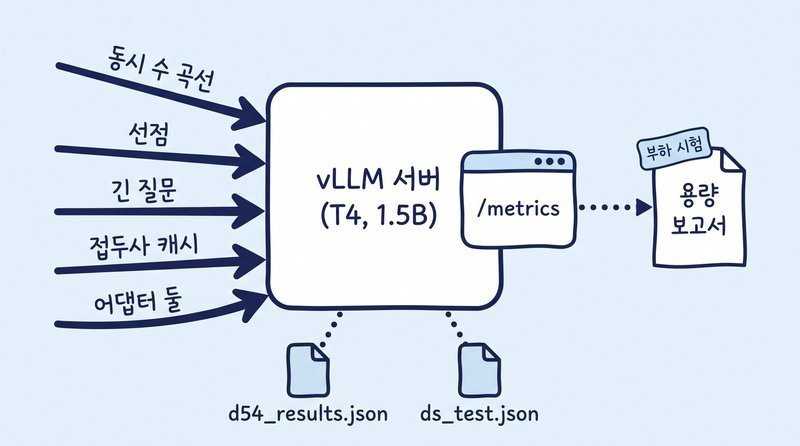

*같은 서버에 설정을 하나씩 바꿔 가며 클라이언트 쪽 측정값과 서버 지표를 함께 적습니다.*

## 이론과 실습을 잇는 순서

| 학습 구간 | 계획 시간 | 연결 위치 |
|---|---:|---|
| 측정 지표 확인과 동시 요청 실험 | 100분 | 이론 1장, Step 0\~2 |
| KV 캐시 부족과 실행 대기 관찰 | 80분 | 이론 2장, Step 3 |
| 입력 순서별 캐시 재사용 확인 | 85분 | 이론 3장, Step 4 |
| 서버 선택과 처리 용량 보고 | 95분 | Step 5\~7 |

이론 설명과 필수 실습을 합쳐 360분으로 계획했습니다. 휴식 40분, 점심 60분, 설치·오류 대응 여유 20분을 포함하면 하루 480분입니다. 표의 연결 위치를 따라 이론을 읽고 해당 실습을 이어서 진행합니다. 선택 실습과 접힌 심화 자료를 모두 추가하지 않습니다. 이 시간은 수업 계획이며 실제 진행 시간을 측정한 값은 아닙니다.

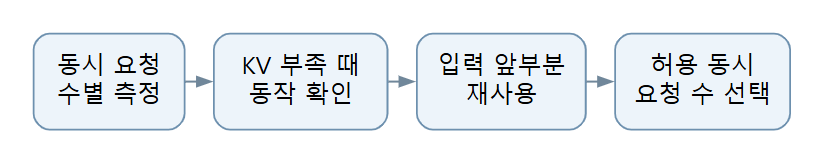

**실습 순서.** 동시 요청 수별 측정 → KV 부족 때 동작 확인 → 입력 앞부분 재사용 → 허용 동시 요청 수 선택 순서로 진행합니다.

### 먼저 읽을 용어

| 용어 | 뜻과 실제로 하는 일 |
|---|---|
| 처리량 |  일정 시간 동안 처리한 요청 수나 생성한 토큰 수 |
| p99 |  측정값을 작은 순서로 놓았을 때 99%가 그 이하인 경계값 |
| 선점 |  다른 요청에 자원을 주기 위해 진행 중인 요청의 실행을 미루는 처리 |
| 프리픽스 캐시 |  여러 입력의 같은 앞부분을 계산한 결과를 다시 사용하는 기능 |

## 실행 환경

이 노트는 **코랩 Pro+의 T4 GPU 런타임**을 기준으로 씁니다. L4에서도 같은 순서로 실행됩니다.

**vLLM 서버는 한 번에 하나만** 기동합니다.

<div style="font-size: 18px; line-height: 1.6;">

| 항목 | 내용 |
|---|---|
| 런타임 | 코랩 Pro+ T4 (16GB). L4·A100도 됨 |
| 로드하는 모델 | Qwen2.5-1.5B-Instruct (vLLM 서버로, 설정을 바꿔 가며 여러 번) |
| 선택 트랙에서 더 로드하는 모델 | 1.5B 4비트·8비트 파일 (트랙 1), Qwen2.5-3B-Instruct (트랙 2) |
| 다운로드하는 파일 | 1.5B 원본 3.1GB, 트랙 2를 하면 3B 원본 6.2GB |
| 앞 노트에서 가져오는 파일 | `ds_test.json`·어댑터(데이터셋 자동화 노트), 부록 실습 C에서 `bench_harness.py`·`d54_results.json`(양자화 노트). 없으면 분기와 공통 준비 코드이 있습니다 |
| 필요한 키 | 없음. 별도 사용 승인 없이 파일을 내려받을 수 있는 공개 저장소만 씁니다 |
| 다음 노트가 읽는 파일 | `/content/d58/d58_capacity.json`(용량 보고서), `/content/d58/bench/c*.json`(부하 테스트) |

</div>

<div style="font-size: 18px; line-height: 1.6;">

| 오래 걸리는 셀 | 하는 일 | T4 기준 대략 (추정) |
|---|---|---|
| Step 0 설치 | vLLM과 torch 2.13 | 3\~6분 |
| 서버 기동 (매번) | 모델 로드, 메모리 측정, CUDA 그래프 캡처 | 1\~4분 |
| Step 2 곡선 | 동시 요청 수 여섯 단계 | 5\~10분 |
| Step 5 어댑터 | 서버 기동과 테스트 세트 | 5\~10분 |
| Step 6 부하 테스트 | 동시 요청 수 네 단계 | 5\~10분 |
| 부록 실습 B 예산 비교 | 서버를 세 번 기동하며 긴 입력 테스트 | 10\~15분 |
| 부록 실습 C 정밀도 | 서버 두세 번과 질문 30개씩 | 8\~12분 |
| 부록 실습 G 어댑터 다시 학습 | 1에폭 두 번 | 15\~30분 |

</div>

**로컬 작업** 표시가 붙은 곳은 사내 GPU 서버에서 달라지는 부분입니다. 코랩에서는 읽고 넘어가도 됩니다.

**RunPod 연장 (선택)**

기본은 위의 코랩 환경입니다. 56·57일차의 팀 예산과 시간이 남은 팀은 같은 네트워크 볼륨을 붙인 Pod(48GB급 1장)를 다시 만들어 본 실습 Step 0\~4와 Step 6을 56일차에 `/workspace/hf`로 받아 둔 32B 4비트 파일(`Qwen/Qwen2.5-32B-Instruct-AWQ`, 19.3GB)로 한 번 더 실행해 봐도 됩니다. Step 5의 어댑터는 1.5B용이라 건너뜁니다.

**바꾸는 것** : Step 0의 버전 확인 셀보다 먼저 `os.environ`에 `MODEL_ID="Qwen/Qwen2.5-32B-Instruct-AWQ"`, `HF_HOME="/workspace/hf"`, `D58_WORK="/workspace/results/d58"`, `D58_WEIGHTS_GB="19.3"`(계산에 4비트 가중치 크기를 씀)을 넣고, KV 캐시가 넉넉하므로 `D58_LEVELS`와 `D58_BENCH_LEVELS`에 64를 더해 무릎을 찾습니다.

**GPU 한 장에는 vLLM 서버를 하나만 기동합니다.** 57일차처럼 팀원 네 명이 측정 하나씩을 맡아 차례로 자기 서버를 기동하고 측정하고 종료합니다.

<div style="font-size: 18px; line-height: 1.6;">

| 역할 | 맡는 것 | 직접 실행하는 셀 | 이름 |
|---|---|---|---|
| A | 동시 요청 수(`D58_LEVELS`)와 곡선의 무릎 | Step 2 서버 기동과 곡선 | |
| B | KV 블록 수(`D58_TIGHT_BLOCKS`)와 선점 | Step 3 보통 서버와 좁은 서버 | |
| C | 프롬프트 순서와 프리픽스 캐시 적중률 | Step 4 | |
| D | 부하 단계(`D58_BENCH_LEVELS`)와 용량 보고서 | Step 6 | |
| 모두 | Step 0\~1, 코랩 결과와 32B 결과 비교, 공유와 정리 | | |

</div>

결과는 코랩의 `d58_capacity.json`과 나란히 놓고 세 수치를 비교합니다(파일 이름과 키는 그대로). 끝나면 서버를 종료하고 Pod를 종료(terminate)해 볼륨만 남깁니다. 요금은 RunPod 요금표에서 확인합니다.

## Step 0. 환경 준비

버전을 고정합니다. vLLM 0.30.0은 torch 2.13.0을 요구하므로 코랩의 torch가 바뀝니다.

In [1]:
!pip install --ignore-installed PyJWT "vllm>=0.30,<0.31"
!pip install -q "peft>=0.21,<0.22"

# 설치가 끝나면 [런타임] - [세션 다시 시작]을 누르고 이 셀 아래부터 실행하세요(torch가 2.13.0으로 바뀝니다).

  Using cached pyjwt-2.15.1-py3-none-any.whl.metadata (3.5 kB)
  Using cached vllm-0.30.0-cp38-abi3-manylinux_2_28_x86_64.whl.metadata (11 kB)


  Using cached regex-2026.11.9-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (40 kB)
  Using cached cachetools-8.0.0-py3-none-any.whl.metadata (5.6 kB)
  Using cached psutil-7.2.2-cp36-abi3-manylinux2010_x86_64.manylinux_2_12_x86_64.manylinux_2_28_x86_64.whl.metadata (22 kB)
  Using cached sentencepiece-0.2.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (34 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached blake3-1.0.11-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.9 kB)
  Using cached py_cpuinfo-9.0.0-py3-none-any.whl.metadata (794 bytes)
  Using cached transformers-5.22.2-py3-none-any.whl.metadata (31 kB)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (9.8 kB)
  Using cached safetensors-0.8.0-cp310-abi3-manylinux_2_17_x86_64.manylinux2014_x8

In [2]:
import gc, json, os, re, shutil, signal, socket, subprocess, sys, threading, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

import httpx
import numpy as np


def pkgver(dist):
    try:
        return version(dist)
    except PackageNotFoundError:
        return "미설치"


print({d: pkgver(d) for d in ["vllm", "torch", "transformers", "peft"]})

{'vllm': '0.30.0', 'torch': '2.13.0', 'transformers': '5.22.2', 'peft': '0.21.2'}


In [3]:
import torch

HAS_GPU = torch.cuda.is_available()
CAP = torch.cuda.get_device_capability(0) if HAS_GPU else None
TOTAL_VRAM = torch.cuda.get_device_properties(0).total_memory / 1e9 if HAS_GPU else None
print(f"GPU : {torch.cuda.get_device_name(0)} / compute capability {CAP} / 메모리 {TOTAL_VRAM:.1f} GB" if HAS_GPU
      else "GPU 런타임이 아닙니다. [런타임] - [런타임 유형 변경]에서 GPU를 고르세요")

SERVE_DTYPE = "half" if (CAP is None or CAP[0] < 8) else "bfloat16"

WORK = Path(os.environ.get("D58_WORK", "/content/d58"))
WORK.mkdir(parents=True, exist_ok=True)
MODEL_ID = os.environ.get("MODEL_ID", "Qwen/Qwen2.5-1.5B-Instruct")
MAX_LEN = int(os.environ.get("D58_MAX_LEN", "4096"))
PORT_BASE = int(os.environ.get("D58_PORT", "8580"))       # 8580부터 열 개
VLLM_BIN = shutil.which("vllm") or "vllm"

print(f"서버 정밀도 {SERVE_DTYPE} / 모델 {MODEL_ID} / 최대 길이 {MAX_LEN} / 작업 폴더 {WORK}")
print(f"vllm 명령 : {VLLM_BIN}")

GPU : NVIDIA A40 / compute capability (8, 6) / 메모리 47.7 GB
서버 정밀도 bfloat16 / 모델 Qwen/Qwen2.5-1.5B-Instruct / 최대 길이 4096 / 작업 폴더 /content/d58
vllm 명령 : /usr/local/bin/vllm


compute capability가 7.5로 출력되면 T4입니다.

## 공통 준비 코드. 하네스 파일 다시 만들기

54일차의 `bench_harness.py`가 작업 폴더에 없을 때 실행합니다. 54일차 실습의 `%%writefile` 셀 여섯 개와 같은 내용이며 현재 폴더에 파일을 만듭니다. 함수 이름과 출력 문구를 바꾸지 않습니다.

In [4]:
%%writefile bench_harness.py
"""54일차 벤치마크 하네스. 55~57일차가 import 해서 씁니다"""
import gc, json, math, os, re, time
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

HAS_GPU = torch.cuda.is_available()
# Step 0 과 같은 규칙 : bf16 은 compute capability 8 이상
DTYPE16 = torch.float16  # 같은 fp16 기준선으로 정밀도 효과를 비교합니다

# 모델 이름은 환경 변수가 있으면 거기서 읽습니다. 서빙 프로젝트에서 들인 습관입니다
MODEL_ID = os.environ.get("D54_MODEL_ID", "Qwen/Qwen2.5-1.5B-Instruct")
# 측정할 때는 GPU 0번에 고정합니다. "auto" 로 두면 메모리가 모자랄 때 조용히 CPU 로 내려가
# 속도 측정값이 엉뚱해집니다(로컬 GPU 배포 노트 4.2절의 로드 방식)
DEVICE_MAP = {"": 0} if HAS_GPU else "cpu"

SYSTEM = "당신은 회사 업무 보조입니다. 답변은 반드시 한국어로만 작성하세요. 묻는 것에만 짧게 답하세요."

TEXT_KO = """한결물산 근무 규정 (실습용으로 지어낸 문서입니다)

제1조 (목적) 이 규정은 한결물산 임직원의 근무 시간, 재택근무, 휴가, 출장, 정보 보안에 관한 기준을 정한다.
제2조 (근무 시간) 기본 근무 시간은 오전 9시부터 오후 6시까지이며 점심시간은 낮 12시부터 1시까지 한 시간이다. 시차 출퇴근제를 신청한 직원은 오전 8시에서 10시 사이에 출근할 수 있다.
제3조 (재택근무) 재택근무는 주 2일까지 신청할 수 있다. 신청은 사용 전날 오후 3시까지 팀장에게 한다. 신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다.
제4조 (연차 휴가) 1년 이상 근무한 직원에게는 연 15일의 연차를 준다. 연차는 반일 단위로 나누어 쓸 수 있다. 3일 이상 연속으로 쓰려면 2주 전까지 신청한다.
제5조 (출장비) 국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다. 식비는 하루 3만 원을 정액으로 지급한다. 출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다.
제6조 (정보 보안) 회사 노트북은 자리를 비울 때 반드시 화면을 잠근다. 고객 정보가 담긴 파일은 외부 메일로 보내지 않는다. 보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.
제7조 (경조 휴가) 본인 결혼 시 5일, 자녀 결혼 시 1일의 경조 휴가를 준다. 부모가 사망한 경우에는 5일을 준다.
제8조 (교육 지원) 직무와 관련된 외부 교육비는 연 100만 원까지 지원한다. 교육을 마친 직원은 2주 안에 결과 보고서를 낸다.
제9조 (장비 대여) 업무용 모니터와 키보드는 총무팀에서 빌릴 수 있다. 빌린 장비는 퇴사 전에 반납한다.
제10조 (법인카드) 법인카드는 업무 목적에만 쓴다. 한 번에 50만 원을 넘는 결제는 재무팀의 사전 승인을 받는다.
제11조 (회의) 정기 회의는 매주 월요일 오전 10시에 연다. 회의록은 회의가 끝난 날 안에 공유한다.
제12조 (개정) 이 규정을 바꿀 때는 시행 2주 전까지 전 직원에게 알린다."""

TEXT_EN = """Hangyeol Trading Work Rules (a document made up for this exercise)

Article 1 (Purpose) These rules set the standards for working hours, remote work, leave, business trips, and information security for employees of Hangyeol Trading.
Article 2 (Working hours) Regular working hours are from 9 a.m. to 6 p.m., and the lunch break is one hour from noon to 1 p.m. Employees who have applied for flexible hours may start work between 8 a.m. and 10 a.m.
Article 3 (Remote work) Employees may apply for remote work up to two days a week. Applications are made to the team leader by 3 p.m. on the day before. New employees may apply for remote work only after three months from joining.
Article 4 (Annual leave) Employees who have worked for one year or more receive 15 days of annual leave a year. Annual leave may be divided into half-day units. To take three or more consecutive days, apply at least two weeks in advance.
Article 5 (Travel expenses) For domestic business trips, accommodation is paid at actual cost up to 100,000 won per night. Meals are paid at a flat rate of 30,000 won per day. Settlement is requested with receipts within five days after the trip ends.
Article 6 (Information security) Company laptops must always be screen-locked when the employee leaves the desk. Files containing customer information are not sent by external email. An employee who learns of a security incident reports it to the security team within one hour.
Article 7 (Family event leave) Employees receive five days of leave for their own wedding and one day for a child's wedding. Five days are given when a parent dies.
Article 8 (Training support) External training related to the job is supported up to 1,000,000 won a year. Employees who complete training submit a report within two weeks.
Article 9 (Equipment rental) Work monitors and keyboards can be borrowed from the general affairs team. Borrowed equipment is returned before leaving the company.
Article 10 (Corporate card) The corporate card is used only for business purposes. Any single payment over 500,000 won requires prior approval from the finance team.
Article 11 (Meetings) The regular meeting is held every Monday at 10 a.m. Minutes are shared on the same day the meeting ends.
Article 12 (Amendment) When these rules change, all employees are notified at least two weeks before they take effect."""

TEXTS = {"ko": TEXT_KO, "en": TEXT_EN}

Overwriting bench_harness.py


In [5]:
%%writefile -a bench_harness.py


LABELS = ["인사", "보안", "재무", "총무"]


def q_rule(qid, rule, question, answer):
    return {"id": qid, "type": "지문", "kind": "num", "answer": answer,
            "q": f"다음 규정을 읽고 답하십시오.\n규정 : {rule}\n질문 : {question} 숫자만 답하십시오."}


def q_calc(qid, question, answer):
    return {"id": qid, "type": "계산", "kind": "num", "answer": answer,
            "q": f"{question} 숫자만 답하십시오."}


def q_label(qid, text, answer):
    return {"id": qid, "type": "분류", "kind": "label", "answer": answer,
            "q": f"다음 문의를 {', '.join(LABELS)} 중 하나로 분류하십시오. 분류 이름 하나만 답하십시오.\n문의 : {text}"}


def q_json(qid, sentence, dept, date):
    return {"id": qid, "type": "형식", "kind": "json", "answer": {"부서": dept, "날짜": date},
            "q": ("다음 문장에서 부서와 날짜를 뽑아 JSON 한 줄로만 답하십시오. "
                  "키는 \"부서\"와 \"날짜\"이고 날짜는 YYYY-MM-DD 형식으로 씁니다.\n"
                  f"문장 : {sentence}")}


QUESTIONS = [
    q_rule("A1", "재택근무는 주 2일까지 신청할 수 있다.", "재택근무는 한 주에 최대 며칠까지 신청할 수 있습니까?", 2),
    q_rule("A2", "신청은 사용 전날 오후 3시까지 팀장에게 한다.", "재택근무 신청은 전날 오후 몇 시까지 해야 합니까?", 3),
    q_rule("A3", "신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다.", "신입 직원은 입사 후 몇 개월이 지나야 재택근무를 신청할 수 있습니까?", 3),
    q_rule("A4", "1년 이상 근무한 직원에게는 연 15일의 연차를 준다.", "1년 이상 근무한 직원의 연차는 1년에 며칠입니까?", 15),
    q_rule("A5", "3일 이상 연속으로 쓰려면 2주 전까지 신청한다.", "연차를 3일 이상 이어서 쓰려면 몇 주 전까지 신청해야 합니까?", 2),
    q_rule("A6", "국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다.", "국내 출장의 1박 숙박비는 최대 몇 만 원까지 받을 수 있습니까? 만 원 단위로", 10),
    q_rule("A7", "출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다.", "출장비 정산은 출장을 마친 뒤 며칠 안에 신청해야 합니까?", 5),
    q_rule("A8", "보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.", "보안 사고를 알게 되면 몇 시간 안에 알려야 합니까?", 1),
    q_calc("B1", "연차 15일 중 4.5일을 썼습니다. 남은 연차는 며칠입니까?", 10.5),
    q_calc("B2", "출장 식비는 하루 3만 원입니다. 4일 출장이면 식비는 모두 몇 만 원입니까? 만 원 단위로", 12),
    q_calc("B3", "숙박비 상한은 1박에 10만 원이고 실제 숙박비는 1박에 8만 원이었습니다. 3박을 했다면 받는 숙박비는 모두 몇 만 원입니까? 만 원 단위로", 24),
    q_calc("B4", "직원 48명 중 25%가 재택근무를 신청했습니다. 신청한 직원은 몇 명입니까?", 12),
    q_calc("B5", "예산 1,200만 원 중 3분의 1을 교육비로 씁니다. 교육비는 몇 만 원입니까? 만 원 단위로", 400),
    q_calc("B6", "오전 9시에 출근해 오후 6시에 퇴근하고 점심시간이 한 시간입니다. 점심시간을 뺀 근무 시간은 몇 시간입니까?", 8),
    q_calc("B7", "반일 연차를 3번, 하루짜리 연차를 2번 썼습니다. 모두 며칠을 썼습니까?", 3.5),
    q_calc("B8", "출장 3일 동안 식비는 하루 3만 원이고 숙박은 2박에 1박당 9만 원이었습니다. 식비와 숙박비를 합하면 모두 몇 만 원입니까? 만 원 단위로", 27),
    q_label("C1", "노트북에 모르는 프로그램이 깔려 있고 창이 계속 뜹니다.", "보안"),
    q_label("C2", "출장비 영수증을 잃어버렸는데 정산은 어떻게 하나요?", "재무"),
    q_label("C3", "육아휴직을 신청하려면 서류를 언제까지 내야 하나요?", "인사"),
    q_label("C4", "회의실 빔프로젝터가 켜지지 않습니다.", "총무"),
    q_label("C5", "고객 명단 파일을 협력사에 메일로 보내도 되나요?", "보안"),
    q_label("C6", "법인카드 한도를 올리고 싶습니다.", "재무"),
    q_label("C7", "신입 사원 교육 일정을 알고 싶습니다.", "인사"),
    q_json("D1", "인사팀은 2026년 3월 4일에 신입 교육을 엽니다.", "인사팀", "2026-03-04"),
    q_json("D2", "2026년 11월 20일에 보안팀이 모의 해킹 훈련을 합니다.", "보안팀", "2026-11-20"),
    q_json("D3", "재무팀의 결산 보고는 2027년 1월 8일입니다.", "재무팀", "2027-01-08"),
    q_json("D4", "총무팀은 2026년 12월 1일부터 사무실 이전을 시작합니다.", "총무팀", "2026-12-01"),
    q_json("D5", "2026년 10월 15일에 영업팀 워크숍이 있습니다.", "영업팀", "2026-10-15"),
    q_json("D6", "개발팀의 배포 일정은 2026년 9월 30일로 잡혔습니다.", "개발팀", "2026-09-30"),
    q_json("D7", "법무팀은 2027년 2월 3일까지 계약서 검토를 마칩니다.", "법무팀", "2027-02-03"),
]

Appending to bench_harness.py


In [6]:
%%writefile -a bench_harness.py


def first_number(text):
    """답에서 처음 나오는 숫자 하나. 천 단위 쉼표는 지웁니다"""
    m = re.search(r"-?\d+(?:\.\d+)?", text.replace(",", ""))
    return float(m.group()) if m else None


def check_answer(ans, kind, expect):
    """채점기. 확인하지 못하면 불합격이 기본입니다"""
    if kind == "num":
        v = first_number(ans)
        return v is not None and abs(v - float(expect)) < 1e-6
    if kind == "label":
        hits = [lab for lab in LABELS if lab in ans]
        return hits == [expect]                 # 둘 이상 말하면 고른 것이 아닙니다
    if kind == "json":
        m = re.fullmatch(r"\s*(\{.*\})\s*", ans, re.S)
        if not m:
            return False
        try:
            obj = json.loads(m.group())
        except json.JSONDecodeError:
            return False
        return all(str(obj.get(k, "")).strip() == v for k, v in expect.items())
    return False

Appending to bench_harness.py


In [7]:
%%writefile -a bench_harness.py


def make_bnb_config(precision):
    """정밀도 이름을 양자화 설정으로 바꿉니다. 인자는 기본값에 맡기지 않고 전부 적습니다"""
    if precision == "16bit":
        return None
    if precision == "int8":
        return BitsAndBytesConfig(load_in_8bit=True, llm_int8_threshold=6.0)
    if precision == "int8_t0":                    # 부록 실습 D : 이상치 분리를 끈 8비트
        return BitsAndBytesConfig(load_in_8bit=True, llm_int8_threshold=0.0)
    if precision == "nf4":
        return BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                  bnb_4bit_compute_dtype=DTYPE16, bnb_4bit_use_double_quant=True)
    if precision == "default4":                   # Step 6 : 한 줄짜리 설정
        return BitsAndBytesConfig(load_in_4bit=True)
    raise ValueError(f"모르는 정밀도 : {precision}")


def vram_gb(peak=False):
    """GPU 메모리(GB). GPU 가 없으면 None 을 반환합니다"""
    if not HAS_GPU:
        return None
    fn = torch.cuda.max_memory_allocated if peak else torch.cuda.memory_allocated
    return fn() / 1e9


def load_model(model_id, precision, pass_dtype=True):
    """모델을 로드해 딕셔너리 하나에 담아 반환합니다. 실패하면 예외 대신 error 를 담아 반환합니다"""
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    kwargs = {"device_map": DEVICE_MAP}
    if pass_dtype:
        kwargs["dtype"] = DTYPE16                 # torch_dtype= 은 폐기되었습니다
    qc = make_bnb_config(precision)
    if qc is not None:
        kwargs["quantization_config"] = qc
    t0 = time.time()
    try:
        tok = AutoTokenizer.from_pretrained(model_id)
        model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        return {"error": "GPU 메모리 부족", "precision": precision}
    except Exception as e:
        return {"error": f"{type(e).__name__}: {str(e)[:160]}", "precision": precision}
    model.eval()
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    return {"model_id": model_id, "precision": precision, "tok": tok, "model": model,
            "load_sec": time.time() - t0, "weights_gb": vram_gb(),
            "footprint_gb": model.get_memory_footprint() / 1e9}


def unload(h):
    """모델을 언로드하고 메모리가 실제로 줄었는지 수치로 보여 줍니다(모델 선택 실습의 방식)"""
    before = vram_gb()
    h["tok"] = h["model"] = None
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        after = vram_gb()
        print(f"  [언로드] GPU 메모리 {before:.2f} -> {after:.2f} GB")
        if before > 0.1 and after > before * 0.3:
            print("  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요")


def describe_layers(model):
    """층마다 어떤 형식으로 로드되었는지 셉니다. Qwen2 계열의 층 이름을 씁니다"""
    kinds = Counter(type(m).__name__ for _, m in model.named_modules()
                    if isinstance(m, nn.Linear) or "Linear" in type(m).__name__)
    q = model.model.layers[0].self_attn.q_proj
    info = {"선형 층": dict(kinds),
            "출력 층": f"{type(model.lm_head).__name__} {model.lm_head.weight.dtype}",
            "임베딩": str(model.model.embed_tokens.weight.dtype),
            "출력 층과 임베딩 공유": bool(getattr(model.config, "tie_word_embeddings", False))}
    if hasattr(q, "compute_dtype"):
        info["4비트 계산 형식"] = str(q.compute_dtype)
        info["4비트 형식"] = getattr(q.weight, "quant_type", "-")
    return info

Appending to bench_harness.py


In [8]:
%%writefile -a bench_harness.py


@torch.no_grad()
def perplexity_top1(h, text, window=512, stride=256):
    """글 한 편의 퍼플렉서티와 위치마다의 1순위 예측을 측정합니다.

    윈도우를 stride 만큼 밀며 새로 들어온 토큰만 채점합니다(허깅페이스 문서의 방식).
    윈도우 크기와 stride 를 바꾸면 값이 바뀌므로 정밀도끼리 비교할 때는 고정합니다(이론 노트 6.2절).
    반환값 : (퍼플렉서티, 1순위 예측 텐서, 채점한 토큰 수)
    """
    tok, model = h["tok"], h["model"]
    ids = tok(text, return_tensors="pt")["input_ids"].to(model.device)
    n = ids.shape[1]
    nll_sum, count, preds, prev_end = 0.0, 0, [], 0
    for begin in range(0, n, stride):
        end = min(begin + window, n)
        x = ids[:, begin:end]
        logits = model(x).logits.float()          # 확률 계산은 32비트로 합니다
        k = min(end - prev_end, x.shape[1] - 1)    # 이번 윈도우에서 새로 채점할 토큰 수
        if k <= 0:                                # 토큰이 하나뿐인 윈도우는 채점할 것이 없습니다
            prev_end = end
            continue
        lg = logits[:, :-1][:, -k:]               # 위치 t 의 출력이 토큰 t+1 을 맞힙니다
        tgt = x[:, 1:][:, -k:]
        nll_sum += F.cross_entropy(lg.reshape(-1, lg.shape[-1]), tgt.reshape(-1),
                                   reduction="sum").item()
        count += tgt.numel()
        preds.append(lg.argmax(-1).flatten().cpu())
        prev_end = end
        if end == n:
            break
    return math.exp(nll_sum / count), torch.cat(preds), count


def chat_inputs(h, user_text):
    """시스템 프롬프트를 붙여 모델 입력을 만듭니다.

    transformers 5 의 apply_chat_template 은 return_tensors="pt" 일 때 텐서가 아니라
    input_ids 와 attention_mask 묶음을 반환합니다. 그래서 return_dict=True 를 적고 묶음으로 씁니다
    """
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_text}]
    enc = h["tok"].apply_chat_template(msgs, add_generation_prompt=True,
                                       return_dict=True, return_tensors="pt")
    return {k: v.to(h["model"].device) for k, v in enc.items()}


@torch.no_grad()
def ask(h, user_text, max_new_tokens=64):
    """샘플링 없이 답 하나를 만듭니다. 실패하면 예외 대신 실패 문자열을 반환합니다"""
    enc = chat_inputs(h, user_text)
    try:
        out = h["model"].generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                  pad_token_id=h["tok"].pad_token_id)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        return "[생성 실패] GPU 메모리 부족"
    return h["tok"].decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()


SPEED_PROMPTS = ["재택근무 규정을 다섯 문장으로 설명해 주세요.",
                 "출장비를 정산하는 순서를 단계별로 적어 주세요.",
                 "정보 보안 수칙 다섯 가지를 설명해 주세요."]


@torch.no_grad()
def tokens_per_sec(h, new_tokens=128):
    """사용자 한 명이 답을 받는 속도. 첫 호출은 준비 시간이 섞여 버리고 측정합니다"""
    ask(h, SPEED_PROMPTS[0], max_new_tokens=8)
    total, t0 = 0, time.time()
    for p in SPEED_PROMPTS:
        enc = chat_inputs(h, p)
        out = h["model"].generate(**enc, max_new_tokens=new_tokens, min_new_tokens=new_tokens,
                                  do_sample=False, pad_token_id=h["tok"].pad_token_id)
        total += out.shape[1] - enc["input_ids"].shape[1]
    if HAS_GPU:
        torch.cuda.synchronize()
    return total / (time.time() - t0)


def measure_all(h, questions=None, texts=None):
    """한 정밀도의 모든 지표를 측정합니다. 기준선과 비교하는 일은 표를 만들 때 합니다"""
    questions = QUESTIONS if questions is None else questions
    texts = TEXTS if texts is None else texts
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    r = {"precision": h["precision"], "model_id": h["model_id"], "load_sec": h["load_sec"], "actual_dtype": str(h["model"].dtype),
         "weights_gb": h["weights_gb"], "footprint_gb": h["footprint_gb"],
         "layers": describe_layers(h["model"]), "ppl": {}, "preds": {}, "answers": {}, "correct": {}}
    for lang, text in texts.items():
        ppl, preds, n = perplexity_top1(h, text)
        r["ppl"][lang], r["preds"][lang] = ppl, preds
    for q in questions:
        ans = ask(h, q["q"], max_new_tokens=96 if q["kind"] == "json" else 48)
        r["answers"][q["id"]] = ans
        r["correct"][q["id"]] = check_answer(ans, q["kind"], q["answer"])
    r["tps"] = tokens_per_sec(h)
    r["peak_gb"] = vram_gb(peak=True)
    return r

Appending to bench_harness.py


In [9]:
%%writefile -a bench_harness.py


# 실습 : 16비트에서 맞힌 것이 틀린 수(맞→틀)와 틀린 것이 맞은 수(틀→맞)를 세는 함수를 완성하세요
# 입력은 둘 다 {질문 id: True/False} dict입니다

def count_flips(base_correct, other_correct):
    ### START CODE HERE ### (맞→틀, 틀→맞 질문 수 세기 2줄)
    # 1) base 에서 True 인데 other 에서 False 인 질문 수. other 에 빠진 질문은 틀린 것으로 칩니다(불합격 기본값)
    to_wrong = sum(1 for k, ok in base_correct.items() if ok and not other_correct.get(k, False))
    # 2) base 에서 False 인데 other 에서 True 인 질문 수
    to_right = sum(1 for k, ok in base_correct.items() if not ok and other_correct.get(k, False))
    ### END CODE HERE ###
    if to_wrong is None or to_right is None:
        return None
    return {"맞→틀": to_wrong, "틀→맞": to_right}


def top1_agreement(base_preds, other_preds):
    """같은 글, 같은 윈도우에서 다음 토큰 1순위가 기준선과 같은 비율"""
    if base_preds is None or other_preds is None or len(base_preds) != len(other_preds):
        return None
    return float((base_preds == other_preds).float().mean())


def fmt(v, spec):
    """값이 없으면(GPU 가 없을 때의 메모리 등) 같은 너비로 '-' 를 출력합니다"""
    if v is None:
        return format("-", re.match(r"[<>^]?\d*", spec).group())
    return format(v, spec)

def measurement_conditions(model_id, dtype16, questions=None):
    """기준선을 재사용할 수 있는 조건. 실측 결과와 조건을 따로 저장합니다."""
    import hashlib
    from importlib.metadata import version, PackageNotFoundError
    from pathlib import Path
    from huggingface_hub import snapshot_download
    questions = QUESTIONS if questions is None else questions
    def digest(value):
        return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
    def installed(name):
        try: return version(name)
        except PackageNotFoundError: return None
    try:
        folder = Path(model_id) if Path(model_id).is_dir() else Path(snapshot_download(model_id, local_files_only=True))
        revision = folder.name if folder.parent.name == "snapshots" else digest(json.loads((folder / "config.json").read_text()))
    except (OSError, ValueError):
        revision = None
    return {"model": str(model_id), "revision": revision, "dtype16": str(dtype16),
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
            "questions": len(questions), "questions_sha256": digest(questions),
            "generation_sha256": digest({"system": SYSTEM, "sample":False, "json_tokens":96, "other_tokens":48}),
            "harness_sha256": hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
            "versions": {n:installed(n) for n in ["torch","transformers","accelerate","bitsandbytes"]}}


def matching_conditions(saved, current):
    return current.get("revision") is not None and all(saved.get(k) == v for k,v in current.items())

Appending to bench_harness.py


## Step 1. 서버 기동·종료 도구와 지표 수집

서버를 기동하는 셀이 여러 번 나오므로 도구로 묶습니다. 서버가 시작하다 멈추면 예외 대신 로그의 오류 줄을 반환합니다.

In [10]:
def pick_port(base, tries=10):
    for port in range(base, base + tries):
        with socket.socket() as probe:
            try:
                probe.bind(("127.0.0.1", port))
                return port
            except OSError:
                continue
    return base


_SERVERS = {}          # 지금 기동되어 있는 서버. GPU 한 장에 하나만 둡니다


def last_error(log_path, n=80):
    lines = Path(log_path).read_text(errors="ignore").splitlines()[-n:] if Path(log_path).exists() else ["(로그 없음)"]
    hits = [l for l in lines if re.search(r"Error|error|not supported|Traceback", l)] or lines
    return hits[-1].strip()[:300]


def stop_proc(proc, timeout=60):
    """엔진이 자식 프로세스라 그룹째 종료합니다"""
    if proc is None or proc.poll() is not None:
        return
    try:
        os.killpg(os.getpgid(proc.pid), signal.SIGTERM)
        proc.wait(timeout=timeout)
    except (ProcessLookupError, subprocess.TimeoutExpired):
        try:
            os.killpg(os.getpgid(proc.pid), signal.SIGKILL)
        except ProcessLookupError:
            pass


def stop_all():
    for name, srv in list(_SERVERS.items()):
        stop_proc(srv.get("proc"))
        srv["logf"].close()
        _SERVERS.pop(name, None)
    time.sleep(3)


def start_vllm(name, extra=(), env=None, model=None, wait=900):
    """기동하고 /health를 기다립니다. 실패하면 ok=False와 오류 줄"""
    stop_all()
    port, model = pick_port(PORT_BASE), model or MODEL_ID
    log_path = WORK / f"server_{name}.log"
    cmd = [VLLM_BIN, "serve", model, "--host", "127.0.0.1", "--port", str(port),
           "--dtype", SERVE_DTYPE, "--max-model-len", str(MAX_LEN), *map(str, extra)]
    logf = open(log_path, "w")
    proc = subprocess.Popen(cmd, stdout=logf, stderr=subprocess.STDOUT,
                            env={**os.environ, **(env or {})}, start_new_session=True)
    srv = {"ok": False, "name": name, "log": log_path, "cmd": cmd, "base": f"http://127.0.0.1:{port}", "model": model}
    t0 = time.time()
    while time.time() - t0 < wait and proc.poll() is None:
        try:
            if httpx.get(srv["base"] + "/health", timeout=2).status_code == 200:
                srv.update(ok=True, proc=proc, logf=logf, start_sec=time.time() - t0)
                _SERVERS[name] = srv
                return srv
        except httpx.HTTPError:
            pass
        time.sleep(2)
    stop_proc(proc)
    logf.close()
    srv["error"] = last_error(log_path) if proc.poll() is not None else f"{wait}초 안에 준비되지 않았습니다"
    return srv


def show(srv):
    if srv.get("ok"):
        print(f"[{srv['name']}] 준비 {srv['start_sec']:.0f}초 / {srv['base']} / 로그 {srv['log'].name}")
    else:
        print(f"[{srv['name']}] 시작 실패 : {srv['error']}")

In [11]:
from prometheus_client.parser import text_string_to_metric_families


def scrape(srv):
    """/metrics를 {이름: 값}으로. 라벨만 다른 샘플은 더합니다"""
    try:
        text = httpx.get(srv["base"] + "/metrics", timeout=10).text
    except (httpx.HTTPError, KeyError) as e:
        return {"_error": str(e)}
    out, info = {}, {}
    for fam in text_string_to_metric_families(text):
        for s in fam.samples:
            if s.name.endswith("_info"):
                info[s.name] = dict(s.labels)
            elif not s.name.endswith("_bucket"):    # 히스토그램 버킷은 더하면 뜻이 없어 뺍니다
                out[s.name] = out.get(s.name, 0.0) + s.value
    out["_info"] = info
    return out


def counter_delta(before, after, name):
    return after[name] - before[name] if (name in before and name in after) else None

In [12]:
BACKENDS = ["TRITON_ATTN", "FLASH_ATTN", "FLASHINFER", "FLEX_ATTENTION"]


def engine_numbers(srv):
    """기동 로그에서 엔진이 잡은 수치를 읽습니다"""
    try:
        text = Path(srv["log"]).read_text(errors="ignore")
    except (OSError, KeyError):
        return {}
    out = {"backend": next((b for b in BACKENDS if b in text), None)}
    m = re.search(r"KV cache size: ([\d,]+) tokens, Maximum concurrency for ([\d,]+) tokens per request: ([\d.]+)x", text)
    out["tokens"] = int(m.group(1).replace(",", "")) if m else None
    out["concurrency"] = float(m.group(3)) if m else None
    return out


def print_rows(rows, cols):
    """cols : (제목, 키, 형식) 목록. 값이 없으면 '-'"""
    print(" ".join(f"{t:>10}" for t, _, _ in cols))
    for r in rows:
        print(" ".join(fmt(r.get(k), ">10" + f) for _, k, f in cols))


def fmt(v, spec):
    if v is None:
        return format("-", re.match(r"[<>^]?\d*", spec).group())
    return format(v, spec)

In [13]:
# 실습 : 두 번 읽은 지표로 그 사이의 프리픽스 캐시 적중률을 내는 함수를 완성하세요(이론 노트 3.2절)

def hit_rate(before, after):
    ### START CODE HERE ### (counter_delta로 물어본 토큰과 찾은 토큰의 차이 구하기 2줄)
    # 1) 물어본 토큰의 차이 : vllm:prefix_cache_queries_total
    q = counter_delta(before, after, "vllm:prefix_cache_queries_total")
    # 2) 찾은 토큰의 차이 : vllm:prefix_cache_hits_total
    h = counter_delta(before, after, "vllm:prefix_cache_hits_total")
    ### END CODE HERE ###
    if q is None or h is None or q <= 0:
        return None
    return h / q

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
q = counter_delta(before, after, "vllm:prefix_cache_queries_total")
h = counter_delta(before, after, "vllm:prefix_cache_hits_total")
```

물어본 토큰이 0이면 그 사이에 요청이 없었다는 뜻이라 적중률을 낼 수 없습니다.

</details>

In [14]:
# 이론 노트 3.2절의 예. 90%가 나오면 맞습니다
test = hit_rate({"vllm:prefix_cache_queries_total": 12000, "vllm:prefix_cache_hits_total": 3000},
                {"vllm:prefix_cache_queries_total": 16000, "vllm:prefix_cache_hits_total": 6600})
print("아직 비어 있습니다. 실습 셀을 채우세요" if test is None else f"적중률 {test:.0%}")

적중률 90%


오늘 여러 Step에서 쓰는 재료를 미리 둡니다.

In [15]:
POLICY_MD = """## 제3조 (근무 시간)
기본 근무 시간은 주 40시간으로 하며, 1일 근무 시간은 휴게 시간을 제외하고 8시간으로 한다. 시업 시각은 오전 10시, 종업 시각은 오후 7시로 하되, 유연근무제 적용자는 제4조에 따른다.

## 제4조 (유연근무제)
임직원은 오전 8시부터 오전 11시 사이에 시업 시각을 자율적으로 선택할 수 있다. 코어 타임은 오전 11시부터 오후 4시까지로 한다.

## 제5조 (재택근무)
임직원은 주 2회 이내에서 재택근무를 신청할 수 있다. 재택근무 신청은 근무일 전일 오후 6시까지 부서장의 승인을 받아야 한다.

## 제7조 (연차 휴가의 이월)
당해 연도에 사용하지 못한 연차 휴가는 다음 연도로 이월할 수 없음을 원칙으로 한다. 다만 회사의 업무상 사유로 사용하지 못한 경우에 한하여 인사팀장의 승인을 받아 최대 5일까지 다음 연도 1분기 내로 이월하여 사용할 수 있다.

## 제8조 (경조 휴가)
본인 결혼 5일, 자녀 결혼 1일, 배우자 출산 10일, 본인 및 배우자의 부모 사망 5일, 조부모 및 형제자매 사망 3일을 부여한다.

## 제10조 (사내 데이터의 외부 반출)
고객 개인정보, 미공개 재무 정보, 기술 설계 문서를 포함한 사내 데이터는 정보보호팀장의 사전 승인 없이 외부로 반출할 수 없다."""

chunks = ["## " + c.strip() for c in POLICY_MD.split("## ") if c.strip()]

SYSTEM_POLICY = """당신은 사내 규정 안내 담당자입니다.
제공된 규정에 근거해서만 답변하고, 근거 조항을 반드시 표기하세요.
규정에 없는 내용이면 확인되지 않는다고 답하세요.
답변은 반드시 한국어로만 작성하세요."""

QA_SET = [
    ("연차를 다음 해로 넘길 수 있나요?", "이월"),
    ("재택근무는 언제까지 신청해야 하나요?", "전일"),
    ("배우자가 출산하면 휴가가 며칠인가요?", "10"),
    ("코어 타임은 몇 시부터인가요?", "11"),
    ("점심시간은 몇 시인가요?", None),
]
print(f"규정 {len(chunks)}조, 질문 {len(QA_SET)}개")

규정 6조, 질문 5개


## Step 2. 동시 요청 수에 따른 처리량·지연 곡선

교재 : 2.4.2 확장성, 9.8 고급 프레임워크 ZeRO와 DeepSpeed

이론 노트 1절의 곡선을 직접 그립니다. 먼저 서버를 기동하고 기동 로그에서 엔진이 잡은 동시 요청 수를 읽어 둡니다(Step 6의 용량 보고서에 씁니다).

그다음 답을 스트리밍으로 받으며 첫 토큰이 온 시각과 청크마다의 간격을 기록하는 함수부터 만듭니다.

In [16]:
BASE_ARGS = ["--enable-prompt-tokens-details"]      # 응답에 cached_tokens(이론 노트 3.2절)
srv = start_vllm("base", BASE_ARGS)
show(srv)
ENGINE = engine_numbers(srv) if srv["ok"] else {}
print("엔진이 잡은 수치 :", ENGINE)

[base] 준비 171초 / http://127.0.0.1:8580 / 로그 server_base.log
엔진이 잡은 수치 : {'backend': 'TRITON_ATTN', 'tokens': 1362528, 'concurrency': 332.65}


In [17]:
SYSTEM_SPEED = "당신은 회사 업무 보조입니다. 답변은 반드시 한국어로만 작성하세요. 묻는 것에만 짧게 답하세요."
CURVE_PROMPT = "재택근무 규정을 다섯 문장으로 설명해 주세요."


def stream_chat(base, model, messages, max_tokens=128, extra=None, timeout=300):
    """스트리밍으로 받으며 첫 토큰 시간과 청크 사이 간격을 잽니다"""
    body = {"model": model, "messages": messages, "max_tokens": max_tokens, "temperature": 0,
            "stream": True, "stream_options": {"include_usage": True}, **(extra or {})}
    t0 = time.perf_counter()
    stamps, pieces, usage, err = [], [], {}, None
    try:
        with httpx.stream("POST", base + "/v1/chat/completions", json=body, timeout=timeout) as r:
            if r.status_code != 200:
                err = f"HTTP {r.status_code} {r.read().decode(errors='ignore')[:150]}"
            for line in (r.iter_lines() if err is None else []):
                if not line.startswith("data: ") or line[6:].strip() == "[DONE]":
                    continue
                chunk = json.loads(line[6:])
                usage = chunk.get("usage") or usage
                for ch in chunk.get("choices", []):
                    piece = (ch.get("delta") or {}).get("content")
                    if piece:
                        stamps.append(time.perf_counter())
                        pieces.append(piece)
    except httpx.HTTPError as e:
        err = f"{type(e).__name__}: {e}"[:200]
    ok = err is None and bool(stamps)
    return {"ok": ok, "error": err, "ttft": stamps[0] - t0 if ok else None,
            "gaps": [b - a for a, b in zip(stamps, stamps[1:])] if ok else [],
            "e2e": time.perf_counter() - t0 if ok else None, "usage": usage if ok else {},
            "text": "".join(pieces), "n_out": usage.get("completion_tokens") if ok else 0}


def pct(values, p):
    vals = [v for v in values if v is not None]
    return float(np.percentile(vals, p)) if vals else None


def run_level(srv, concurrency, n_requests=None, max_tokens=128, extra=None, messages_fn=None, model_fn=None):
    """동시 요청 수를 고정해 n_requests개를 보냅니다(이론 노트 6.2절)"""
    n_requests = n_requests or max(8, concurrency * 4)
    messages_fn = messages_fn or (lambda i: [{"role": "system", "content": SYSTEM_SPEED}, {"role": "user", "content": CURVE_PROMPT}])
    model_fn = model_fn or (lambda i: srv["model"])
    t0 = time.perf_counter()
    with ThreadPoolExecutor(max_workers=concurrency) as ex:
        res = list(ex.map(lambda i: stream_chat(srv["base"], model_fn(i), messages_fn(i), max_tokens, extra),
                          range(n_requests)))
    dur = time.perf_counter() - t0
    ok = [r for r in res if r["ok"]]
    gaps = [g for r in ok for g in r["gaps"]]
    return {"동시": concurrency, "요청": n_requests, "실패": len(res) - len(ok),
            "처리량": sum(r["n_out"] for r in ok) / dur if ok and all(r["n_out"] is not None for r in ok) else None,
            "ttft_p50": pct([r["ttft"] for r in ok], 50), "ttft_p99": pct([r["ttft"] for r in ok], 99),
            "chunk_gap_p50": pct(gaps, 50), "chunk_gap_p99": pct(gaps, 99), "e2e_p99": pct([r["e2e"] for r in ok], 99),
            "초": dur, "_res": res}

### 응답 조각의 도착 간격과 토큰 생성 간격

서버는 여러 토큰을 모아 응답 조각인 청크 하나로 보낼 수 있습니다. 특히 한국어에서는 토큰이 생성돼도 바로 읽을 수 있는 글자가 완성되지 않을 수 있습니다. 따라서 클라이언트에 텍스트 청크가 도착한 간격과 서버가 토큰을 생성한 간격을 구분합니다.

자체 함수의 `chunk_gap_p99`는 비어 있지 않은 텍스트 청크 사이의 도착 간격입니다. Step 6의 벤치마크 도구가 보고한 토큰 간 지연 ITL·토큰당 생성 시간 TPOT와는 별도로 기록합니다. 토큰 처리량은 서버가 실제 생성 토큰 수인 `completion_tokens`를 제공한 경우에만 계산합니다.

출력 길이는 `ignore_eos`로 128토큰에 고정합니다.

In [18]:
CURVE_EXTRA = {"ignore_eos": True}
LEVELS = [int(x) for x in os.environ.get("D58_LEVELS", "1,2,4,8,16,32").split(",")]
SLO_TTFT = float(os.environ.get("D58_SLO_TTFT", "2.0"))     # 초
SLO_ITL = float(os.environ.get("D58_SLO_ITL", "0.1"))       # 초


def find_knee(rows, gain=0.10):
    """처리량이 gain보다 덜 오르기 직전 단계를 무릎으로 봅니다"""
    ok = [r for r in rows if r["처리량"]]
    for a, b in zip(ok, ok[1:]):
        if b["처리량"] < a["처리량"] * (1 + gain):
            return a["동시"]
    return ok[-1]["동시"] if ok else None

In [19]:
# 실습 : 곡선 표에서 SLO를 만족하는 운영점을 고르는 함수를 완성하세요(이론 노트 1.3절)

def pick_operating_point(rows, slo_ttft=SLO_TTFT, slo_itl=SLO_ITL):
    ### START CODE HERE ### (SLO를 만족한 행만 남긴 목록 만들기 4줄)
    # 1) 실패가 0이고 ttft_p99 <= slo_ttft, itl_p99 <= slo_itl 인 행만 남깁니다(None인 필드는 불합격)
    passed = [r for r in rows
              if r["실패"] == 0 and r["처리량"] is not None
              and r["ttft_p99"] is not None and r["ttft_p99"] <= slo_ttft
              and r["chunk_gap_p99"] is not None and r["chunk_gap_p99"] <= slo_itl]
    ### END CODE HERE ###
    if passed is None:
        return None
    if not passed:
        return 0
    return max(passed, key=lambda r: r["처리량"])["동시"]

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
passed = [r for r in rows
          if r["실패"] == 0 and r["처리량"] is not None
          and r["ttft_p99"] is not None and r["ttft_p99"] <= slo_ttft
          and r["chunk_gap_p99"] is not None and r["chunk_gap_p99"] <= slo_itl]
```

첫 응답 시간이나 청크 사이 간격을 측정하지 못한 행을 합격으로 처리하면, 응답 목표를 지켰다는 확인 없이 더 많은 동시 요청을 허용하게 됩니다.

</details>

In [20]:
if srv.get("ok"):
    run_level(srv, 1, 3, max_tokens=16)            # 예열. 첫 요청에는 준비 시간이 섞입니다
    curve = [run_level(srv, c, max_tokens=128, extra=CURVE_EXTRA) for c in LEVELS]
    print_rows(curve, [("동시", "동시", "d"), ("실패", "실패", "d"), ("처리량", "처리량", ".0f"), ("ttft p50", "ttft_p50", ".2f"),
                       ("ttft p99", "ttft_p99", ".2f"), ("chunk gap p50", "chunk_gap_p50", ".3f"), ("chunk gap p99", "chunk_gap_p99", ".3f")])
    (WORK / "curve.json").write_text(json.dumps([{k: v for k, v in r.items() if k != "_res"} for r in curve],
                                                ensure_ascii=False, indent=1))
    op = pick_operating_point(curve)
    print(f"\n무릎 : 동시 {find_knee(curve)} / SLO(p99 첫 토큰 {SLO_TTFT}초, p99 간격 {SLO_ITL}초) 안의 운영점 : "
          f"{'빈칸' if op is None else op}")

        동시         실패        처리량   ttft p50   ttft p99 chunk gap p50 chunk gap p99
         1          0        132       0.10       0.11      0.007      0.015
         2          0        253       0.12       0.15      0.007      0.015
         4          0        493       0.14       0.18      0.007      0.016
         8          0        903       0.22       0.26      0.007      0.019
        16          0       1221       0.72       0.85      0.007      0.023
        32          0       1508       1.21       2.83      0.008      0.079

무릎 : 동시 32 / SLO(p99 첫 토큰 2.0초, p99 간격 0.1초) 안의 운영점 : 16


**그래프에서 실제 운영할 동시 요청 수 선택하기**

1. 처리량이 잘 늘다가 증가 폭이 작아지는 지점의 동시 요청 수를 찾습니다. 이 지점을 곡선의 무릎이라고 합니다.
2. 첫 응답 시간과 텍스트 청크 도착 간격이 모두 목표를 지키는 행 중 가장 큰 동시 요청 수를 찾습니다.
3. 1번과 2번에서 찾은 요청 수 중 작은 값을 실제 서비스에서 허용할 동시 요청 수로 고릅니다.

같은 표를 그래프로 그리는 셀은 부록 실습 H에 있습니다.

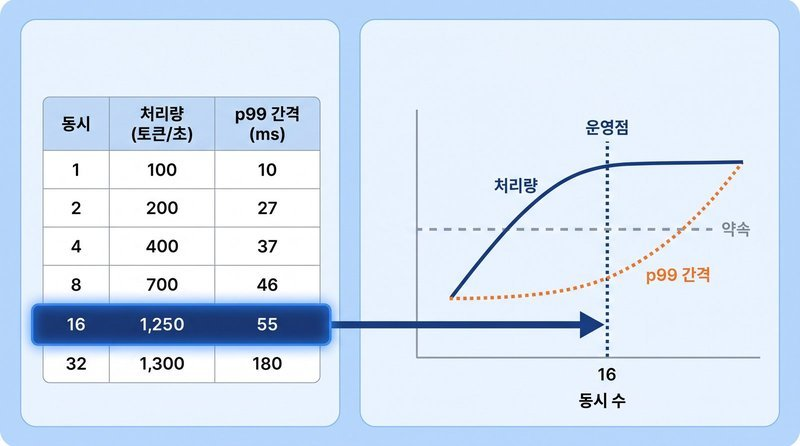

*응답 목표를 지키는 최대 동시 요청 수와 처리량 증가가 둔해지는 지점의 요청 수를 비교해, 두 값 중 작은 값을 운영에 사용합니다.*

## Step 3. KV 블록 수를 줄인 서버의 선점

이론 노트 2절의 선점을 일부러 일으킵니다. KV 블록을 128개(2,048토큰)로 줄이고 같은 부하를 보통 서버와 좁은 서버에 차례로 겁니다.

In [21]:
TIGHT_BLOCKS = int(os.environ.get("D58_TIGHT_BLOCKS", "128"))     # 블록 128개 = 2,048토큰
TIGHT_LEN = 1024                    # 블록 수를 넘으면 시작 거절
PREEMPT_LOAD = {"concurrency": 8, "n_requests": 16, "max_tokens": 512, "extra": {"ignore_eos": True}}


def watch(srv, fn, every=0.5):
    """fn을 실행하는 동안 게이지의 최고점을 기록합니다"""
    peaks, stop = {"kv_max": 0.0, "waiting_max": 0.0}, threading.Event()

    def poll():
        while not stop.is_set():
            m = scrape(srv)
            peaks["kv_max"] = max(peaks["kv_max"], m.get("vllm:kv_cache_usage_perc", 0.0))
            peaks["waiting_max"] = max(peaks["waiting_max"], m.get("vllm:num_requests_waiting", 0.0))
            stop.wait(every)

    th = threading.Thread(target=poll, daemon=True)
    th.start()
    try:
        result = fn()
    finally:
        stop.set()
        th.join(timeout=5)
    return result, peaks


def preempt_run(srv):
    before = scrape(srv)
    row, peaks = watch(srv, lambda: run_level(srv, **PREEMPT_LOAD))
    after = scrape(srv)
    row["선점"] = counter_delta(before, after, "vllm:num_preemptions_total")
    s = counter_delta(before, after, "vllm:request_num_preemptions_sum")
    n = counter_delta(before, after, "vllm:request_num_preemptions_count")
    row["요청당_선점"] = (s / n) if (s is not None and n) else None
    row.update(peaks)
    return row

In [22]:
rows_preempt = {}
if srv.get("ok"):
    rows_preempt["보통"] = preempt_run(srv)

tight = start_vllm("tight", ["--num-gpu-blocks-override", TIGHT_BLOCKS, "--max-model-len", TIGHT_LEN, *BASE_ARGS])
show(tight)
if tight["ok"]:
    print("좁은 서버의 엔진 수치 :", engine_numbers(tight))
    rows_preempt["좁음"] = preempt_run(tight)

print_rows([{"서버": k, **r} for k, r in rows_preempt.items()],
           [("서버", "서버", ""), ("선점", "선점", ".0f"), ("요청당", "요청당_선점", ".2f"), ("KV 최고", "kv_max", ".0%"),
            ("대기 최고", "waiting_max", ".0f"), ("처리량", "처리량", ".0f"), ("e2e p99", "e2e_p99", ".1f")])

[tight] 준비 67초 / http://127.0.0.1:8580 / 로그 server_tight.log
좁은 서버의 엔진 수치 : {'backend': 'TRITON_ATTN', 'tokens': 2048, 'concurrency': 2.0}
        서버         선점        요청당      KV 최고      대기 최고        처리량    e2e p99
        보통          0       0.00         0%          0       1007        4.2
        좁음         28       1.75       100%          4        756        5.5


**표를 읽는 순서**

1. 좁은 서버에서 선점 수가 0보다 크고 KV 최고가 100% 가까이인지 봅니다  
2. 같은 일을 다시 계산했으므로 좁은 서버의 처리량이 낮고 e2e p99가 길어야 합니다

서버 로그에서도 선점을 확인합니다.

In [23]:
if tight.get("ok"):
    lines = [l for l in Path(tight["log"]).read_text(errors="ignore").splitlines() if "Preemptions" in l]
    print(f"Preemptions 필드가 붙은 로그 줄 {len(lines)}개 :", lines[-1].strip()[-120:] if lines else "")
stop_all()

Preemptions 필드가 붙은 로그 줄 0개 : 


## Step 4. 프리픽스 캐시 적중률

컨텍스트와 하네스 노트 코드 트랙 5의 두 순서와 이론 노트 3.3절의 순서 C를 같은 질문 다섯 개로 측정하고 vLLM 지표로 적중률을 냅니다.

In [24]:
srv = start_vllm("base", BASE_ARGS)          # 앞 Step에서 종료했으니 다시 기동합니다
show(srv)

from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(MODEL_ID)
CTX = "\n\n".join(chunks)
T0 = time.time()


def build_messages(order, q, i=0):
    """순서 A·B(컨텍스트와 하네스 노트)와 시각을 맨 앞에 둔 C"""
    if order == "A":                      # [시스템][규정 원문][질문]
        return [{"role": "system", "content": SYSTEM_POLICY},
                {"role": "user", "content": f"[규정]\n{CTX}\n\n질문: {q}"}]
    if order == "B":                      # [질문][시스템][규정 원문]
        return [{"role": "system", "content": f"질문: {q}\n\n" + SYSTEM_POLICY},
                {"role": "user", "content": f"[규정]\n{CTX}"}]
    if order == "C":                      # 순서 A의 맨 앞에 초 단위 시각 한 줄
        stamp = time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(T0 + i))
        return [{"role": "system", "content": f"현재 시각 : {stamp}\n" + SYSTEM_POLICY},
                {"role": "user", "content": f"[규정]\n{CTX}\n\n질문: {q}"}]
    raise ValueError(order)


def prompt_ids(messages):
    """서버가 보는 것과 같은 토큰 열"""
    text = tok.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
    return tok(text, add_special_tokens=False)["input_ids"]


def common_prefix_len(a, b):
    return next((i for i, (x, y) in enumerate(zip(a, b)) if x != y), min(len(a), len(b)))


BLOCK = 16                          # vLLM의 기본 KV 블록 크기(이론 노트 3.1절)

[base] 준비 47초 / http://127.0.0.1:8580 / 로그 server_base.log


In [25]:
# 실습 : 요청을 차례로 보낼 때 캐시에서 찾을 토큰 수를 추정하는 함수를 완성하세요(이론 노트 3.1절, 3.3절)

def predict_hit_rate(id_lists, block=BLOCK):
    hits, total, seen = 0, 0, []
    for ids in id_lists:
        best = max((common_prefix_len(prev, ids) for prev in seen), default=0)
        ### START CODE HERE ### (캐시에서 찾을 토큰 수를 블록 단위로 추정하기 1줄)
        # 1) best와 len(ids) - 1(마지막 토큰은 늘 다시 계산) 중 작은 값을 block의 배수로 내립니다
        cached = (min(best, len(ids) - 1) // block) * block
        ### END CODE HERE ###
        if cached is None:
            return None
        hits += cached
        total += len(ids)
        seen.append(ids)
    return hits / total if total else None

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
cached = (min(best, len(ids) - 1) // block) * block
```

두 번째 요청부터 공통 시작이 길수록 적중이 늘고 블록에 못 미치는 끝부분은 버려집니다.

</details>

In [26]:
def measure_order(srv, order):
    msgs_list = [build_messages(order, q, i) for i, (q, _) in enumerate(QA_SET)]
    ids_list = [prompt_ids(m) for m in msgs_list]
    before = scrape(srv)
    rows = [stream_chat(srv["base"], srv["model"], m, max_tokens=150) for m in msgs_list]   # 그 노트의 150토큰
    after = scrape(srv)
    usage = [r.get("usage") or {} for r in rows]
    cached = sum(((u.get("prompt_tokens_details") or {}).get("cached_tokens") or 0) for u in usage)
    prompt = sum((u.get("prompt_tokens") or 0) for u in usage)
    return {"순서": order, "예측": predict_hit_rate(ids_list), "지표": hit_rate(before, after),
            "요청합": cached / prompt if prompt else None, "프롬프트": prompt,
            "ttft_p50": pct([r["ttft"] for r in rows], 50), "실패": sum(not r["ok"] for r in rows)}


rows_prefix = [measure_order(srv, o) for o in ["A", "B", "C"]] if srv.get("ok") else []

show_rate = lambda v: "빈칸" if v is None else f"{v:.0%}"
print_rows(rows_prefix, [("순서", "순서", ""), ("예측", "예측", ".0%"), ("지표", "지표", ".0%"), ("요청합", "요청합", ".0%"),
                         ("프롬프트 토큰", "프롬프트", "d"), ("ttft p50", "ttft_p50", ".3f"), ("실패", "실패", "d")])

        순서         예측         지표        요청합    프롬프트 토큰   ttft p50         실패
         A        76%        76%        76%       2712      0.108          0
         B         0%         0%         0%       2712      0.085          0
         C         2%         2%         2%       2842      0.073          0


**표를 읽는 순서**

1. 순서 A의 지표가 높고 순서 B와 C는 0에 가까워야 합니다  
2. 예측과 지표가 몇 퍼센트 안에서 맞아야 합니다  
3. 지표(서버 전체)와 요청합(응답의 `cached_tokens`)이 서로 맞는지 봅니다(이론 노트 3.2절)

어댑터 비교는 선택 실습입니다. 준비된 어댑터와 평가 세트가 없으면 이 Step의 실행을 건너뛰고 Step 6으로 진행합니다. 필수 과제는 부하 곡선·선점·프리픽스 캐시·운영점이며, 새 어댑터 학습 시간을 하루 계획에 추가하지 않습니다.

## Step 5. 베이스 모델 하나에 어댑터 둘

교재 : 5.5.2 어댑터

데이터셋 자동화 노트 코드 Step 8의 어댑터 둘(원본으로 학습한 `ab_uncurated`, 큐레이션으로 학습한 `ab_curated`)을 1.5B 서버 하나에 붙이고 그 노트의 테스트 세트로 다시 측정합니다.

**어댑터와 테스트 세트**

- 분기 1 : 두 어댑터 폴더에 `adapter_config.json`이 있고 `ds_test.json`이 있으면 그대로 씁니다  
- 그렇지 않으면 첫 셀이 알려 주는 대로 **부록 실습 G**에서 어댑터(다시 학습하거나 테스트용으로 만들기)와 대신 쓸 테스트 세트를 준비하고 이 Step의 둘째 셀부터 이어 갑니다. 테스트용 어댑터는 **구조만** 확인합니다

In [27]:
MAX_LORA_RANK = int(os.environ.get("D58_MAX_LORA_RANK", "16"))
AB_DIRS = {"ab_uncurated": Path(os.environ.get("D58_AB_A", "./ab_uncurated")),
           "ab_curated": Path(os.environ.get("D58_AB_B", "./ab_curated"))}
DS_DIR = Path(os.environ.get("D58_DS_DIR", "."))


def check_adapter(path, base_model=MODEL_ID, max_rank=MAX_LORA_RANK):
    """vLLM이 받는 어댑터인지 봅니다(이론 노트 5.3절). 빈 목록이면 통과"""
    cfg_path = Path(path) / "adapter_config.json"
    if not cfg_path.exists():
        return ["adapter_config.json 없음"]
    c = json.loads(cfg_path.read_text())
    checks = [(c.get("r", 0) > max_rank, f"r {c.get('r')} > max_lora_rank {max_rank}"),
              (bool(c.get("modules_to_save")), "modules_to_save 있음"), (bool(c.get("use_dora")), "DoRA"),
              (c.get("bias", "none") != "none", f"bias {c.get('bias')}"),
              (c.get("base_model_name_or_path") not in (base_model, base_model.split("/")[-1]),
               f"베이스 모델이 다름 : {c.get('base_model_name_or_path')}")]
    return [msg for bad, msg in checks if bad]


status = {name: check_adapter(p) for name, p in AB_DIRS.items()}
print({name: probs or "통과" for name, probs in status.items()})

TEST_FILE = DS_DIR / "ds_test.json"
if not TEST_FILE.exists():
    TEST_FILE = WORK / "ds_test_fallback.json"           # 부록 실습 G가 만드는 대신 쓰는 세 건
BRANCH = 1 if all(not p for p in status.values()) else 3
if BRANCH == 3 or not TEST_FILE.exists():
    print("부록 실습 G에서 어댑터나 테스트 세트를 준비한 뒤 이 Step의 다음 셀로 돌아오세요")

{'ab_uncurated': ['adapter_config.json 없음'], 'ab_curated': ['adapter_config.json 없음']}
부록 실습 G에서 어댑터나 테스트 세트를 준비한 뒤 이 Step의 다음 셀로 돌아오세요


`--max-loras`를 어댑터 수에 맞춥니다(이론 노트 5.2절).

In [28]:
lora_args = ["--enable-lora", "--max-loras", len(AB_DIRS), "--max-lora-rank", MAX_LORA_RANK,
             "--lora-modules", *[f"{n}={p}" for n, p in AB_DIRS.items()], *BASE_ARGS]
lsrv = start_vllm("lora", lora_args)
show(lsrv)
if lsrv["ok"]:
    print("서버의 모델 :", [m["id"] for m in httpx.get(lsrv["base"] + "/v1/models", timeout=10).json()["data"]])
    e = engine_numbers(lsrv)
    print(f"KV 토큰 : 어댑터 없이 {fmt(ENGINE.get('tokens'), ',')} → LoRA 슬롯 {len(AB_DIRS)}개 {fmt(e.get('tokens'), ',')}")

[lora] 시작 실패 : (APIServer pid=4379) ValueError: Loading lora ab_uncurated failed: No adapter found for ab_uncurated


`/v1/models`에 베이스 모델과 어댑터 이름이 함께 보여야 합니다. KV 토큰이 줄었다면 그만큼이 LoRA 슬롯에 할당된 메모리입니다.

In [29]:
SYSTEM_PROMPT_D45 = ("당신은 사내 회의록을 표준 양식으로 정리하는 담당자입니다. "
                     "요청한 양식만 출력하고, 답변은 반드시 한국어로 작성합니다.")
TEST_ITEMS = json.loads(TEST_FILE.read_text(encoding="utf-8")) if TEST_FILE.exists() else []
print(f"테스트 세트 : {TEST_FILE.name} {len(TEST_ITEMS)}건")

테스트 세트 : ds_test_fallback.json 0건


In [30]:
# 실습 : 답이 회의록 표준 양식을 지켰는지 보는 함수를 완성하세요
# QLoRA 실습의 양식 : 네 제목이 이 순서로 나오고 결정 사항의 번호 줄마다 "담당"과 "기한"이 있어야 합니다
HEADINGS = ["## 회의 개요", "## 결정 사항", "## 논의 사항", "## 후속 조치"]


def format_ok(text):
    ### START CODE HERE ### (네 제목이 처음 나오는 위치의 목록 만들기 1줄)
    # 1) HEADINGS 각각이 text에서 처음 나오는 위치(없으면 -1)의 목록
    pos = [text.find(h) for h in HEADINGS]
    ### END CODE HERE ###
    if pos is None:
        return None
    if -1 in pos or pos != sorted(pos):
        return False
    decided = text[pos[1]:pos[2]]
    items = [l for l in decided.splitlines() if re.match(r"\s*\d+\.", l)]
    return bool(items) and all(("담당" in l and "기한" in l) for l in items)

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
pos = [text.find(h) for h in HEADINGS]
```

제목이 하나라도 없거나 순서가 바뀌면 불합격입니다.

</details>

In [31]:
def adapter_eval(srv, models, items, workers=8, system=None):
    """모델마다 양식 통과율. 요청을 섞어 보내 여러 어댑터가 한 스텝에 계산됩니다"""
    jobs = [(m, it) for it in items for m in models]

    def one(job):
        m, it = job
        msgs = [{"role": "system", "content": system or SYSTEM_PROMPT_D45},
                {"role": "user", "content": f"{it['instruction']}\n\n{it['input']}"}]
        return m, stream_chat(srv["base"], m, msgs, max_tokens=400)

    with ThreadPoolExecutor(max_workers=workers) as ex:
        res = list(ex.map(one, jobs))
    table = {}
    for m, r in res:
        t = table.setdefault(m, {"n": 0, "pass": 0, "blank": False, "ttft": [], "fail": 0, "sample": ""})
        t["n"] += 1
        ok = format_ok(r["text"]) if r["ok"] else False
        t["fail"] += not r["ok"]
        t["blank"] |= ok is None
        t["pass"] += bool(ok)
        t["ttft"].append(r["ttft"])
        t["sample"] = t["sample"] or r["text"][:80]
    return table


if lsrv.get("ok"):
    models = [lsrv["model"], *AB_DIRS.keys()]
    table = adapter_eval(lsrv, models, TEST_ITEMS)
    print(f"{'모델':<30} {'건수':>4} {'실패':>4} {'양식 통과':>9} {'ttft p50':>9}")
    print("-" * 62)
    for m in models:
        t = table[m]
        rate = "빈칸" if t["blank"] else f"{t['pass']}/{t['n'] - t['fail']}"
        print(f"{m[-30:]:<30} {t['n']:>4} {t['fail']:>4} {rate:>9} {fmt(pct(t['ttft'], 50), '>9.2f')}")
    for m in models:
        print(f"\n[{m}] {table[m]['sample']!r}")
stop_all()

**표를 읽는 순서**

1. 실패가 0이고 세 모델의 답이 서로 다른지 봅니다  
2. 분기 1이라면 큐레이션 어댑터의 통과율이 원본 어댑터보다 높은지 봅니다  
3. 분기 3이라면 통과율은 읽지 않습니다

베이스 모델만 호출할 때와 세 모델을 섞어 호출할 때의 처리량 비교는 부록 실습 E에서 LoRA 슬롯 수와 함께 측정합니다.

 **로컬 작업** : 어댑터 카드의 베이스 모델과 버전을 `check_adapter`처럼 서버를 기동하기 전에 검사하는 단계를 배포 절차에 넣습니다.

## Step 6. 부하 테스트와 용량 보고서

교재 : 2.4.2 확장성, 7.2.1 실패 모드 조기 탐지

서빙 프로젝트 노트 4절은 `ThreadPoolExecutor`로 동시 요청 1, 2, 4, 6개를 보내 **최대 응답 시간**이 SLO 0.6초 안인 가장 큰 동시 요청 수를 찾고 메모리 계산 한계와 비교해 작은 값을 용량으로 적었습니다. 오늘은 같은 일을 vLLM 서버에 합니다. 달라지는 것은 셋입니다.

- 부하는 `vllm bench serve`로 겁니다. 동시 요청 수를 고정하고 단계마다 요청을 충분히 보냅니다(이론 노트 6.2절)
- SLO는 최대값 대신 p99로 봅니다. Step 2와 같은 p99 첫 토큰 시간 2초, p99 토큰 사이 간격 0.1초입니다
- 계산 한계와 실측 한계 사이에 엔진이 잡은 동시 요청 수를 하나 더 놓습니다(이론 노트 6.4절)

같은 시간에 서버의 `/metrics`도 읽습니다.

In [32]:
srv = start_vllm("base", BASE_ARGS)
show(srv)
ENGINE = engine_numbers(srv) if srv["ok"] else ENGINE     # Step 2와 같은 설정이라 같은 값이어야 합니다

BENCH_LEVELS = [int(x) for x in os.environ.get("D58_BENCH_LEVELS", "1,4,16,32").split(",")]
BENCH_IN, BENCH_OUT = 512, 128
BENCH_DIR = WORK / "bench"                 # 79일차 노트가 c1.json을 읽습니다
BENCH_DIR.mkdir(exist_ok=True)


def bench(srv, concurrency, num_prompts=None):
    num_prompts = num_prompts or max(16, concurrency * 8)
    name = f"c{concurrency}.json"
    cmd = [VLLM_BIN, "bench", "serve", "--backend", "openai", "--base-url", srv["base"],
           "--endpoint", "/v1/completions", "--model", srv["model"],
           "--dataset-name", "random", "--random-input-len", str(BENCH_IN), "--random-output-len", str(BENCH_OUT),
           "--num-prompts", str(num_prompts), "--max-concurrency", str(concurrency), "--ignore-eos",
           "--percentile-metrics", "ttft,tpot,itl,e2el", "--metric-percentiles", "50,99",
           "--goodput", f"ttft:{int(SLO_TTFT * 1000)}", f"tpot:{int(SLO_ITL * 1000)}",
           "--save-result", "--result-dir", str(BENCH_DIR), "--result-filename", name]
    run, peaks = watch(srv, lambda: subprocess.run(cmd, capture_output=True, text=True, timeout=1800))
    path = BENCH_DIR / name
    if run.returncode != 0 or not path.exists():
        return {"동시": concurrency, "error": (run.stderr or run.stdout).strip().splitlines()[-1:] or ["?"]}
    res = json.loads(path.read_text())
    res.update({"동시": concurrency, **peaks})
    return res


bench_rows = []
if srv.get("ok"):
    before = scrape(srv)
    for c in BENCH_LEVELS:
        r = bench(srv, c)
        bench_rows.append(r)
        print(f"동시 {c} 끝" if "error" not in r else f"동시 {c} 실패 : {r['error']}")
    preempt_total = counter_delta(before, scrape(srv), "vllm:num_preemptions_total")
    print(f"부하 테스트 동안의 선점 : {preempt_total}")

[base] 준비 47초 / http://127.0.0.1:8580 / 로그 server_base.log
동시 1 끝
동시 4 끝
동시 16 끝
동시 32 끝
부하 테스트 동안의 선점 : 0.0


In [33]:
print_rows(bench_rows, [("동시", "동시", "d"), ("완료", "completed", "d"), ("실패", "failed", "d"),
                        ("출력 토큰/초", "output_throughput", ".0f"), ("ttft p50 ms", "p50_ttft_ms", ".0f"),
                        ("ttft p99 ms", "p99_ttft_ms", ".0f"), ("itl p99 ms", "p99_itl_ms", ".0f"),
                        ("goodput", "request_goodput", ".2f"), ("대기 최고", "waiting_max", ".0f"), ("KV 최고", "kv_max", ".0%")])
for r in bench_rows:
    if "error" in r:
        print(f"동시 {r['동시']} 실패 : {r['error']}")

        동시         완료         실패    출력 토큰/초 ttft p50 ms ttft p99 ms itl p99 ms    goodput      대기 최고      KV 최고
         1         16          0        136         46        102         12       1.06          0         0%
         4         32          0        513         83        103         12       4.01          0         0%
        16        128          0       1637        199        318         24      12.79          7         1%
        32        256          0       2644        193        577         65      20.66         14         1%


`goodput`은 SLO를 만족한 요청만 센 초당 요청 수입니다(이론 노트 6.3절). 이 표의 측정값과 Step 2에서 직접 만든 함수로 낸 곡선을 같은 동시 요청 수에서 비교해 봅니다.

보고서의 첫 수치인 **계산한 동시 요청 수**를 모델 선택 노트 코드의 식으로 냅니다.

In [34]:
from huggingface_hub import hf_hub_download, get_safetensors_metadata

cfg = json.loads(Path(hf_hub_download(MODEL_ID, "config.json")).read_text())
LAYERS = cfg["num_hidden_layers"]
KV_HEADS = cfg.get("num_key_value_heads") or cfg["num_attention_heads"]
HEAD_DIM = cfg.get("head_dim") or cfg["hidden_size"] // cfg["num_attention_heads"]

try:
    N_PARAMS = sum(get_safetensors_metadata(MODEL_ID).parameter_count.values())
except Exception:                       # 메타데이터를 못 읽으면 계산을 건너뜁니다
    N_PARAMS = None


def kv_bytes_per_token(kv_dtype="auto"):
    """2(K, V) × 층 × KV 헤드 × 헤드 차원 × 2바이트(이론 노트 4.1절)"""
    return LAYERS * KV_HEADS * 2 * HEAD_DIM * 2


WEIGHTS_GB = os.environ.get("D58_WEIGHTS_GB")      # 4비트 파일은 크기(GB)를 직접 넣습니다


def calc_capacity(kv_dtype="auto", seq=MAX_LEN):
    """모델 선택 노트 코드의 방식 : GPU 메모리의 90%, 가중치에 15% 여유"""
    if TOTAL_VRAM is None or (N_PARAMS is None and not WEIGHTS_GB):
        return None
    weights_gb = float(WEIGHTS_GB) if WEIGHTS_GB else N_PARAMS * 2 / 1e9     # 기본은 16비트 가중치
    kv_room_gb = TOTAL_VRAM * 0.9 - weights_gb * 1.15
    tokens = kv_room_gb * 1e9 / kv_bytes_per_token(kv_dtype)
    return {"weights_gb": weights_gb, "kv_room_gb": kv_room_gb, "tokens": tokens, "concurrency": tokens / seq}


CALC = calc_capacity()
print(f"토큰 하나의 KV {kv_bytes_per_token():,}바이트 / 계산 :", CALC and {k: round(v, 2) for k, v in CALC.items()})

토큰 하나의 KV 28,672바이트 / 계산 : {'weights_gb': 3.09, 'kv_room_gb': 39.38, 'tokens': 1373437.75, 'concurrency': 335.31}


토큰 하나의 KV가 16비트에서 28,672바이트로 출력되면 이론 노트 4.1절의 계산과 같습니다.

이론 노트 6.4절의 세 수치와 항목을 한 파일에 담습니다. 키 이름의 `약속`은 SLO, `손잡이`는 설정값입니다. 뒤의 노트들이 이 파일 이름(`d58_capacity.json`)과 키를 그대로 읽으므로 바꾸지 않습니다.

In [35]:
# 실습 : 부하 테스트 표에서 SLO를 만족한 가장 큰 동시 요청 수를 구해 보고서를 완성하세요

### START CODE HERE ### (SLO를 만족한 단계를 고르고 그 가운데 가장 큰 동시 요청 수 구하기 5줄)
# 1) 조건 : 실패 0, p99_ttft_ms <= SLO_TTFT * 1000, p99_itl_ms <= SLO_ITL * 1000 (없는 필드는 불합격)인 단계의 동시 요청 수 목록
passed = [r["동시"] for r in bench_rows
          if "error" not in r and r.get("failed", 1) == 0
          and r.get("p99_ttft_ms") is not None and r["p99_ttft_ms"] <= SLO_TTFT * 1000
          and r.get("p99_itl_ms") is not None and r["p99_itl_ms"] <= SLO_ITL * 1000]
# 2) 그 가운데 가장 큰 값. 그런 단계가 없으면 0입니다
slo_conc = max(passed) if passed else 0
### END CODE HERE ###

numbers = {"계산한_동시수": CALC["concurrency"] if CALC else None,
           "엔진이_잡은_동시수": ENGINE.get("concurrency"),
           "약속을_지킨_동시수": slo_conc}
known = [v for v in numbers.values() if v is not None]
report = {
    "조건": {"모델": MODEL_ID, "GPU": torch.cuda.get_device_name(0) if HAS_GPU else None,
             "vllm": pkgver("vllm"), "입력_토큰": BENCH_IN, "출력_토큰": BENCH_OUT, "최대_길이": MAX_LEN},
    "약속": {"ttft_p99_초": SLO_TTFT, "itl_p99_초": SLO_ITL},
    "손잡이": {"max_num_seqs": "기본(256)", "max_num_batched_tokens": "기본(2048)",
             "gpu_memory_utilization": "기본(0.92)", "kv_cache_dtype": "auto", "max_loras": "어댑터 없음"},
    "세_숫자": numbers,
    "서비스_한계": min(known) if (known and slo_conc is not None) else None,
    "선점": preempt_total if "preempt_total" in globals() else None,
    "접두사_캐시_적중률_A": rows_prefix[0]["지표"] if rows_prefix else None,
    "다시_잴_조건": ["모델이나 버전을 바꿀 때", "입력 길이가 달라질 때", "부서나 어댑터가 늘 때"],
}
if slo_conc is None:
    print("아직 비어 있습니다. SLO를 만족한 동시 요청 수를 채우고 이 셀을 다시 실행하세요")
else:
    (WORK / "d58_capacity.json").write_text(json.dumps(report, ensure_ascii=False, indent=1, default=str))
    print(json.dumps(report["세_숫자"], ensure_ascii=False), "→ 서비스 한계", report["서비스_한계"])

{"계산한_동시수": 335.3119502476284, "엔진이_잡은_동시수": 339.36, "약속을_지킨_동시수": 32} → 서비스 한계 32


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
passed = [r["동시"] for r in bench_rows
          if "error" not in r and r.get("failed", 1) == 0
          and r.get("p99_ttft_ms") is not None and r["p99_ttft_ms"] <= SLO_TTFT * 1000
          and r.get("p99_itl_ms") is not None and r["p99_itl_ms"] <= SLO_ITL * 1000]
slo_conc = max(passed) if passed else 0
```

`failed`가 없으면 1로 읽어 불합격으로 칩니다.

</details>

보고서의 세 수치(`세_숫자`) 가운데 가장 작은 값이 서비스의 한계입니다.

 **로컬 작업** : 사내 보고서에는 실제 질문 로그의 입력과 출력 길이 분포로 다시 측정한 결과를 씁니다.

## Step 7. 선택 심화 트랙

두 트랙 중 **하나 이상을 선택**해 수행하고 공유합니다. RunPod 연장을 하는 팀은 트랙 대신 본 실습 Step 2\~4와 Step 6을 32B 4비트로 다시 실행합니다(실행 환경의 RunPod 연장 셀).

<div style="font-size: 18px; line-height: 1.6;">

| 트랙 | 주제 | 성격 | 난이도 |
|---|---|---|---|
| 1 | 4비트 가중치와 8비트 계산의 곡선 | 비교 | 상 |
| 2 | QLoRA 실습의 3B 어댑터 서빙 (평가용) | 확장 | 중 |

</div>

#### 트랙 1. 4비트 가중치와 8비트 계산의 곡선
교재 : 5.7 자원 제약 장치용 모델 최적화, 9.6.2 정밀도 스케일링

같은 모델의 4비트 가중치 파일(W4A16)과 8비트 가중치·8비트 활성값 파일(W8A8)을 차례로 기동해 Step 2의 곡선을 그립니다. 기본 경로는 56일차가 RunPod 볼륨에 남긴 7B 폴더(`/workspace/results/d56`)이고 코랩에서 4비트 폴더가 없으면 허깅페이스의 1.5B GPTQ 파일로 대신합니다. W8A8은 GPTQ·AWQ 실습 노트 부록 실습 F의 llm-compressor 스크립트를 방식 W8A8로 실행해 만들어 둔 팀만 측정합니다.

In [36]:
W4_PATH = os.environ.get("D58_W4A16", "/workspace/results/d56/7b-gptq-ko")
W4_MODEL = W4_PATH if Path(W4_PATH).exists() else "Qwen/Qwen2.5-1.5B-Instruct-GPTQ-Int4"
W8_MODEL = os.environ.get("D58_W8A8", "/workspace/results/d56/7b-llmc-w8a8")

curves_q = {}
for label, model in [("W4A16", W4_MODEL), ("W8A8", W8_MODEL)]:
    if label == "W8A8" and not Path(model).exists():
        print(f"{label} 파일이 없습니다 : {model}")
        continue
    s = start_vllm(f"t2_{label}", BASE_ARGS, model=model)
    show(s)
    if not s["ok"]:
        continue
    run_level(s, 1, 2, max_tokens=16)
    curves_q[label] = [run_level(s, c, max_tokens=128, extra=CURVE_EXTRA) for c in [1, 4, 16, 32]]
stop_all()

for label, rows in curves_q.items():
    print(label, [(r["동시"], None if r["처리량"] is None else round(r["처리량"])) for r in rows])

[t2_W4A16] 준비 94초 / http://127.0.0.1:8580 / 로그 server_t2_W4A16.log
W8A8 파일이 없습니다 : /workspace/results/d56/7b-llmc-w8a8
W4A16 [(1, 104), (4, 397), (16, 1022), (32, 1098)]


두 곡선이 엇갈리는 지점이 있다면 그 동시 요청 수가 이론 노트 1장 심화 ‘4비트 가중치와 8비트 계산의 선택 기준’의 선택 기준입니다.

#### 트랙 2. QLoRA 실습의 3B 어댑터 서빙 (평가용)

QLoRA 실습이 남긴 `./qlora_adapter`를 Qwen2.5-3B-Instruct 서버에 붙입니다. 3B는 Qwen Research License라서 이 트랙의 결과는 **평가용**으로만 씁니다.

In [37]:
QLORA_DIR = Path(os.environ.get("D58_QLORA_DIR", "./qlora_adapter"))
QLORA_BASE = os.environ.get("D58_QLORA_BASE", "Qwen/Qwen2.5-3B-Instruct")
SYSTEM_PROMPT_D35 = "당신은 사내 문서를 정리하는 어시스턴트입니다. 답변은 반드시 한국어로 작성합니다."

probs = check_adapter(QLORA_DIR, base_model=QLORA_BASE)
print("어댑터 검사 :", probs or "통과")
if not probs:
    s3 = start_vllm("qlora3b", ["--enable-lora", "--max-loras", 1, "--max-lora-rank", MAX_LORA_RANK,
                                "--lora-modules", f"qlora={QLORA_DIR}", *BASE_ARGS], model=QLORA_BASE)
    show(s3)
    if s3["ok"]:
        t3 = adapter_eval(s3, [QLORA_BASE, "qlora"], TEST_ITEMS[:3], system=SYSTEM_PROMPT_D35)
        for m, t in t3.items():
            print(f"{m:<28} 양식 통과 {t['pass']}/{t['n']}")
    stop_all()

어댑터 검사 : ['adapter_config.json 없음']


QLoRA 실습은 양식 지시문 없이 학습했으므로 같은 질문에 베이스 모델은 양식을 잘 못 지키고 어댑터는 지켜야 합니다.

## Step 8. 공유와 정리

각자 수행한 트랙을 공유합니다.

**1. 선택한 트랙과 측정 결과**

**2. 곡선과 운영점** : Step 2에서 처리량 증가가 둔해진 동시 요청 수, 응답 시간 목표를 지키도록 고른 요청 수, Step 6에서 확인한 요청 수를 비교해 선택이 타당한지

**3. 선점과 캐시** : Step 3의 선점 수와 e2e p99, 순서 A·B·C의 적중률(예측과 지표)

**4. 용량 보고서** : `d58_capacity.json`의 세 수치와 서비스 한계, 어댑터를 붙였을 때 바뀐 KV 캐시 토큰 수. RunPod 연장을 했다면 32B 보고서를 나란히 놓습니다

**계측 없는 파이프라인은 스크립트입니다.**

In [38]:
stop_all()
try:
    left = subprocess.run(["pgrep", "-f", "vllm serve"], capture_output=True, text=True).stdout.split()
except FileNotFoundError:
    left = ["(pgrep 없음, nvidia-smi로 확인하세요)"]
print("남은 vllm 프로세스 :", left or "없음")

남은 vllm 프로세스 : 없음


### 혼자 설명하기

동시 요청 수를 늘렸더니 초당 생성 토큰 수와 p99 첫 응답 시간이 모두 늘었습니다. 기술적으로 받을 수 있는 요청 수와 응답 시간 목표를 지키며 운영할 요청 수를 구분해 직접 그린 그래프로 설명합니다.

| 자기 점검 | 남길 근거 |
|---|---|
| [목표 1] 바꾸고 실행한 내용 | 사용한 입력과 설정, 실제 출력 |
| [목표 2] 비교한 결과와 판단 | 그대로 둔 설정과 바꾼 설정, 직접 측정한 결과인지 여부 |
| [목표 3] 다시 실행할 때 필요한 기록 | 저장한 파일과 선택에 사용한 측정값 |

D59에서는 모델·GPU·입출력 길이 등 비교 조건을 다른 서빙 엔진의 결과와도 맞출 수 있는지 확인합니다.

## 마무리 과제. 사내 vLLM 서버 용량 보고서

여러분이 맡을 사내 LLM 서비스 하나를 정해 용량 보고서를 씁니다.

**1단계. 조건 정하기**

1. 서비스, 모델과 버전, GPU를 적습니다.  
2. 실제 질문의 입력과 출력 길이 분포를 적습니다.  
3. SLO를 정합니다. p99 첫 토큰 시간과 p99 토큰 사이 간격의 목표를 수치로 적습니다.

**2단계. 측정**

4. 동시 요청 수를 두 배씩 늘린 곡선을 그리고 무릎과 운영점을 찾습니다.  
5. 피크 시간의 초당 요청 수로 한 번 더 측정합니다.  
6. 시스템 프롬프트와 고정 문서의 순서를 점검하고 프리픽스 캐시 적중률을 부하와 함께 적습니다.

**3단계. 설정 고르기**

7. `max_num_seqs`, `max_num_batched_tokens`, `kv_cache_dtype` 가운데 하나 이상을 바꿔 전후를 같은 조건으로 측정합니다.  
8. 어댑터를 쓴다면 `max_loras`를 실제 어댑터 수에 맞춰 섞인 부하로 측정합니다.

**4단계. 보고서**

9. 세 수치(계산, 엔진, SLO)와 서비스 한계를 적고 다시 측정할 조건을 적습니다.

**평가 기준**

- 모든 지연 측정값이 동시 요청 수, 입력·출력 길이와 함께 적혀 있는가  
- 평균이 아니라 p50과 p99로 적었는가  
- 설정을 바꾼 전후가 같은 조건으로 측정되었는가  
- 실패 수와 선점 수를 확인했는가  
- 서비스 한계가 세 수치 가운데 가장 작은 값으로 정해졌는가

## 부록 실습 A. 계산한 KV 캐시 크기와 엔진이 확보한 메모리 크기

본 실습을 마친 뒤 시간이 남거나 더 깊이 보고 싶을 때 하는 실습입니다. 본 실습 Step 6까지 실행한 상태에서 시작합니다. 본 실습 끝에서 서버를 모두 종료했으므로 부록마다 필요한 서버를 다시 기동합니다.

본 실습 Step 6에서 모델 선택 노트 코드의 식으로 계산한 값(`CALC`)을 서버를 기동해 엔진이 실제로 잡은 수치와 항목별로 비교합니다.

In [39]:
srv = start_vllm("base", BASE_ARGS)
show(srv)
ENGINE = engine_numbers(srv) if srv["ok"] else {}
log_text = Path(srv["log"]).read_text(errors="ignore")
for key, pat in [("weights_gib", r"Model loading took ([\d.]+) GiB"), ("kv_gib", r"Available KV cache memory: ([\d.]+) GiB")]:
    m = re.search(pat, log_text)
    ENGINE[key] = float(m.group(1)) if m else None
GIB = 1024 ** 3 / 1e9                     # 1 GiB = 1.074 GB
print(f"어텐션 백엔드 : {ENGINE.get('backend')}")
print(f"{'항목':<16} {'계산':>12} {'엔진':>12}")
print("-" * 44)
calc = CALC or {}
w_eng = ENGINE.get("weights_gib") * GIB if ENGINE.get("weights_gib") else None
kv_eng = ENGINE.get("kv_gib") * GIB if ENGINE.get("kv_gib") else None
print(f"{'가중치(GB)':<16} {fmt(calc.get('weights_gb'), '>12.2f')} {fmt(w_eng, '>12.2f')}")
print(f"{'KV 메모리(GB)':<16} {fmt(calc.get('kv_room_gb'), '>12.2f')} {fmt(kv_eng, '>12.2f')}")
print(f"{'담는 토큰':<16} {fmt(calc.get('tokens'), '>12,.0f')} {fmt(ENGINE.get('tokens'), '>12,')}")
print(f"{'동시(배)':<16} {fmt(calc.get('concurrency'), '>12.1f')} {fmt(ENGINE.get('concurrency'), '>12.2f')}")

[base] 준비 55초 / http://127.0.0.1:8580 / 로그 server_base.log
어텐션 백엔드 : TRITON_ATTN
항목                         계산           엔진
--------------------------------------------
가중치(GB)                  3.09         3.20
KV 메모리(GB)              39.38        39.86
담는 토큰               1,373,438    1,390,032
동시(배)                   335.3       339.36


**표를 읽는 순서**

1. 어텐션 백엔드가 `TRITON_ATTN`인지 봅니다  
2. 가중치는 계산과 엔진이 거의 같아야 합니다  
3. KV 메모리는 대개 엔진 쪽이 작습니다

**로컬 작업** : 사내 GPU에서는 `TOTAL_VRAM` 대신 그 GPU에서 실제로 쓸 수 있는 메모리를 넣습니다.

## 부록 실습 B. 긴 입력 하나와 한 스텝의 토큰 예산

짧은 요청 여섯 개가 디코드하는 중에 6천 토큰 안팎의 긴 입력 하나를 보냅니다. 한 스텝의 토큰 예산(`--max-num-batched-tokens`)을 512, 2048(기본값), 8192로 바꿔 짧은 요청의 가장 긴 토큰 간격과 긴 입력의 첫 토큰 시간을 측정합니다(이론 노트 2장 심화 ‘한 스텝의 토큰 예산 선택’).

In [40]:
import secrets

LONG_REPEAT = int(os.environ.get("D58_LONG_REPEAT", "10"))
LONG_TEXT = "\n\n".join(f"[사본 {i + 1}]\n{POLICY_MD}" for i in range(LONG_REPEAT))
BUDGETS = [int(x) for x in os.environ.get("D58_BUDGETS", "512,2048,8192").split(",")]
LONG_LEN = 8192                     # 긴 입력이 들어가도록 이 Step만 최대 길이를 늘립니다


def long_prompt_scenario(srv, n_short=6, short_tokens=256, head_start=1.0):
    """짧은 요청들이 디코드를 시작한 뒤 긴 입력을 보내 두 지표를 측정합니다"""
    short_msgs = lambda i: [{"role": "system", "content": SYSTEM_SPEED}, {"role": "user", "content": CURVE_PROMPT}]
    long_msgs = [{"role": "system", "content": SYSTEM_POLICY},
                 {"role": "user", "content": f"[규정]\n{LONG_TEXT}\n\n질문: 재택근무는 언제까지 신청해야 하나요?"}]
    box = {}

    def shorts():
        with ThreadPoolExecutor(max_workers=n_short) as ex:
            box["short"] = list(ex.map(lambda i: stream_chat(srv["base"], srv["model"], short_msgs(i),
                                                             short_tokens, {"ignore_eos": True}), range(n_short)))

    th = threading.Thread(target=shorts)
    th.start()
    time.sleep(head_start)
    long_r = stream_chat(srv["base"], srv["model"], long_msgs, max_tokens=32,
                         extra={"cache_salt": secrets.token_urlsafe(16)})
    th.join()
    short = [r for r in box.get("short", []) if r["ok"]]
    gaps = [g for r in short for g in r["gaps"]]
    return {"긴_ttft": long_r["ttft"], "긴_토큰": (long_r.get("usage") or {}).get("prompt_tokens"),
            "짧은_간격_p50": pct(gaps, 50), "짧은_간격_최대": max(gaps) if gaps else None,
            "실패": (n_short - len(short)) + (0 if long_r["ok"] else 1)}

In [41]:
rows_budget = {}
for b in BUDGETS:
    s = start_vllm(f"budget{b}", ["--max-num-batched-tokens", b, "--max-model-len", LONG_LEN])
    show(s)
    if not s["ok"]:
        rows_budget[b] = {"error": s["error"]}
        continue
    run_level(s, 1, 2, max_tokens=16)              # 예열
    r = long_prompt_scenario(s)
    r["kv_tokens"] = engine_numbers(s).get("tokens")
    rows_budget[b] = r
stop_all()

print(f"\n{'예산':>6} {'긴 입력 토큰':>11} {'긴 입력 ttft':>12} {'짧은 간격 p50':>13} {'짧은 간격 최대':>14} {'KV 토큰':>9} {'실패':>4}")
print("-" * 80)
for b, r in rows_budget.items():
    if "error" in r:
        print(f"{b:>6} 시작 실패 : {r['error']}")
        continue
    print(f"{b:>6} {fmt(r['긴_토큰'], '>11')} {fmt(r['긴_ttft'], '>12.2f')} {fmt(r['짧은_간격_p50'], '>13.3f')} "
          f"{fmt(r['짧은_간격_최대'], '>14.3f')} {fmt(r['kv_tokens'], '>9,')} {r['실패']:>4}")

[budget512] 준비 69초 / http://127.0.0.1:8580 / 로그 server_budget512.log
[budget2048] 준비 71초 / http://127.0.0.1:8580 / 로그 server_budget2048.log
[budget8192] 준비 75초 / http://127.0.0.1:8580 / 로그 server_budget8192.log

    예산     긴 입력 토큰    긴 입력 ttft     짧은 간격 p50       짧은 간격 최대     KV 토큰   실패
--------------------------------------------------------------------------------
   512        4607         0.34         0.007          0.045 1,362,864    0
  2048        4607         0.27         0.007          0.077 1,362,528    0
  8192        4607         0.28         0.007          0.146 1,360,992    0


**표를 읽는 순서**

1. 예산이 작을수록 짧은 요청의 가장 긴 간격이 작아야 합니다  
2. 예산이 클수록 긴 입력의 첫 토큰 시간이 짧아야 합니다  
3. KV 토큰 열도 봅니다. 예산을 키우면 스텝마다의 작업 메모리가 늘어 KV 캐시 메모리가 줄어듭니다(이론 노트 2장 심화 ‘한 스텝의 토큰 예산 선택’)

## 부록 실습 C. KV 캐시 정밀도와 벤치마크 하네스

54일차가 만든 `bench_harness.py`를 작업 폴더(코랩은 드라이브 폴더, RunPod는 /workspace)에 둡니다. 없으면 공통 준비 코드를 먼저 실행합니다. 질문 30개와 채점기, flip을 세는 `count_flips`를 그 파일에서 불러옵니다.

In [42]:
# 54일차 벤치마크 하네스(bench_harness.py)에서 질문 세트와 채점기를 불러옵니다
HARNESS_DIR = os.environ.get("BENCH_HARNESS_DIR", "/content")
if not (Path(HARNESS_DIR) / "bench_harness.py").exists():
    print(f"{HARNESS_DIR}/bench_harness.py 가 없습니다. 앞의 공통 준비 코드을 먼저 실행하세요")
sys.path.insert(0, HARNESS_DIR)
from bench_harness import SYSTEM, LABELS, QUESTIONS, check_answer, count_flips

SELF_TEST = [
    ("2일입니다.", "num", 2, True), ("주 3일", "num", 2, False), ("10.5", "num", 10.5, True),
    ("1,200만 원", "num", 1200, True), ("모르겠습니다", "num", 3, False),
    ("보안", "label", "보안", True), ("보안팀 소관입니다", "label", "보안", True),
    ("보안 또는 총무", "label", "보안", False), ("재무", "label", "보안", False),
    ('{"부서": "인사팀", "날짜": "2026-03-04"}', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, True),
    ('```json\n{"부서": "인사팀", "날짜": "2026-03-04"}\n```', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, False),
    ('{"부서": "인사", "날짜": "2026-03-04"}', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, False),
    ("부서는 인사팀입니다", "json", {"부서": "인사팀", "날짜": "2026-03-04"}, False),
]
bad = [(a, k, e) for a, k, e, want in SELF_TEST if check_answer(a, k, e) != want]
print(f"질문 {len(QUESTIONS)}개 :", dict(Counter(q["type"] for q in QUESTIONS)))
print(f"채점기 검산 {len(SELF_TEST)}건 중 어긋남 {len(bad)}건")

/content/bench_harness.py 가 없습니다. 앞의 공통 준비 코드을 먼저 실행하세요
질문 30개 : {'지문': 8, '계산': 8, '분류': 7, '형식': 7}
채점기 검산 13건 중 어긋남 0건


채점기 검산의 어긋남이 0건이어야 다음으로 갑니다.

In [43]:
srv = start_vllm("base", BASE_ARGS)
show(srv)


def ask_server(srv, user_text, max_tokens=64, model=None):
    """샘플링 없이 답 하나를 받습니다. 실패하면 예외 대신 실패 문자열을 반환합니다"""
    body = {"model": model or srv["model"], "temperature": 0, "max_tokens": max_tokens,
            "messages": [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_text}]}
    try:
        r = httpx.post(srv["base"] + "/v1/chat/completions", json=body, timeout=120)
    except httpx.HTTPError as e:
        return f"[생성 실패] {type(e).__name__}"
    if r.status_code != 200:
        return f"[생성 실패] HTTP {r.status_code}"
    return (r.json()["choices"][0]["message"]["content"] or "").strip()


def measure_quality(srv, name):
    """질문 30개의 답과 맞고 틀림. 벤치마크 하네스의 measure_all에서 정답과 flip 항목만 서버로 옮겼습니다"""
    r = {"name": name, "answers": {}, "correct": {}}
    for q in QUESTIONS:
        ans = ask_server(srv, q["q"], max_tokens=96 if q["kind"] == "json" else 48)
        r["answers"][q["id"]] = ans
        r["correct"][q["id"]] = check_answer(ans, q["kind"], q["answer"])
    return r


quality = {}
kv_rows = {}
if srv.get("ok"):
    quality["vllm_auto"] = measure_quality(srv, "vllm_auto")
    kv_rows["auto"] = {"ok": True, **engine_numbers(srv)}
    print(f"vLLM auto 정답 {sum(quality['vllm_auto']['correct'].values())}/{len(QUESTIONS)}")

[base] 준비 53초 / http://127.0.0.1:8580 / 로그 server_base.log
vLLM auto 정답 18/30


In [44]:
D54_CANDIDATES = [Path(os.environ.get("D58_D54_RESULTS", "d54_results.json")), Path("/content/d54_results.json"),
                  Path("/content/d55/d54_results.json")]  # 마지막은 55일차 프루닝 실습의 작업 폴더
D54_FILE = next((p for p in D54_CANDIDATES if p.exists()), None)
d54_base = None
if D54_FILE:
    saved = json.loads(D54_FILE.read_text(encoding="utf-8"))
    cond = saved.get("_conditions", {})
    if cond.get("model") == MODEL_ID and cond.get("questions") == len(QUESTIONS) and "correct" in saved.get("16bit", {}):
        d54_base = saved["16bit"]["correct"]
        print(f"{D54_FILE} 의 16비트 행을 엔진 쪽 기준선으로 씁니다 (그때 버전 {cond.get('versions')})")
    else:
        print(f"{D54_FILE} 의 조건이 달라 쓰지 않습니다 : {cond.get('model')}, 질문 {cond.get('questions')}")
else:
    print("d54_results.json이 없습니다. 엔진 쪽 flip은 '기준 없음'으로 출력됩니다")

d54_results.json이 없습니다. 엔진 쪽 flip은 '기준 없음'으로 출력됩니다


`fp8`은 T4에서 시작 단계에 거절될 것으로 예상하는 형식이고(이론 노트 4.2절) `int8_per_token_head`는 소스상 T4의 후보입니다.

In [45]:
# 형식마다 토큰 하나의 KV 캐시 바이트(이론 노트 4.2절의 스케일 바이트 포함). 본 실습 Step 6의 같은 이름 함수를 바꿔 씁니다
def kv_bytes_per_token(kv_dtype="auto"):
    if kv_dtype in ("auto", "float16", "half", "bfloat16"):
        per_head = 2 * HEAD_DIM * 2                 # K와 V, 숫자 하나 2바이트
    elif kv_dtype == "int8_per_token_head":
        per_head = 2 * HEAD_DIM * 1 + 2 * 4         # K와 V 1바이트씩 + 32비트 스케일 둘
    elif kv_dtype == "int4_per_token_head":
        per_head = 2 * (HEAD_DIM // 2) + 2 * 4      # 4비트 둘을 1바이트에 + 스케일 둘
    elif kv_dtype.startswith("fp8"):
        per_head = 2 * HEAD_DIM * 1                 # 층마다 스케일 하나라 토큰마다 붙는 바이트가 없습니다
    else:
        return None
    return LAYERS * KV_HEADS * per_head


KV_DTYPES = os.environ.get("D58_KV_DTYPES", "fp8,int8_per_token_head").split(",")

for d in KV_DTYPES:
    s = start_vllm(f"kv_{d}", ["--kv-cache-dtype", d, *BASE_ARGS])
    show(s)
    if not s["ok"]:
        kv_rows[d] = {"ok": False, "error": s["error"]}
        continue
    kv_rows[d] = {"ok": True, **engine_numbers(s)}
    quality[f"vllm_{d}"] = measure_quality(s, f"vllm_{d}")
stop_all()

[kv_fp8] 준비 112초 / http://127.0.0.1:8580 / 로그 server_kv_fp8.log
[kv_int8_per_token_head] 준비 65초 / http://127.0.0.1:8580 / 로그 server_kv_int8_per_token_head.log


In [46]:
base_ok = quality.get("vllm_auto", {}).get("correct")
print(f"{'KV 형식':<22} {'시작':>4} {'KV 토큰':>10} {'동시(배)':>8} {'정답':>6} {'맞→틀':>5} {'틀→맞':>5}")
print("-" * 70)
for d, row in kv_rows.items():
    if not row["ok"]:
        print(f"{d:<22} {'실패':>4}  {row['error'][:70]}")
        continue
    q = quality.get(f"vllm_{d}" if d != "auto" else "vllm_auto")
    acc = sum(q["correct"].values()) if q else None
    flips = count_flips(base_ok, q["correct"]) if (base_ok and q) else None
    print(f"{d:<22} {'성공':>4} {fmt(row.get('tokens'), '>10,')} {fmt(row.get('concurrency'), '>8.2f')} "
          f"{fmt(acc, '>3')}/{len(QUESTIONS):<2} {fmt(flips and flips['맞→틀'], '>5')} {fmt(flips and flips['틀→맞'], '>5')}")

if d54_base and base_ok:
    f = count_flips(d54_base, base_ok)
    print(f"\n엔진 쪽 flip (transformers 16비트 → vLLM auto) : 맞→틀 {f['맞→틀']}, 틀→맞 {f['틀→맞']}")
else:
    print("\n엔진 쪽 flip : 기준 없음")

calc8 = calc_capacity("int8_per_token_head")
if calc8 and CALC:
    print(f"계산으로 본 KV 캐시 토큰 수 : 16비트 {CALC['tokens']:,.0f}토큰 / int8_per_token_head {calc8['tokens']:,.0f}토큰 "
          f"({calc8['tokens'] / CALC['tokens']:.2f}배)")

KV 형식                    시작      KV 토큰    동시(배)     정답   맞→틀   틀→맞
----------------------------------------------------------------------
auto                     성공  1,390,032   339.36  18/30     0     0
fp8                      성공  2,698,880   658.91   9/30    13     4
int8_per_token_head      성공  2,642,640   645.18  22/30     1     5

엔진 쪽 flip : 기준 없음
계산으로 본 KV 캐시 토큰 수 : 16비트 1,373,438토큰 / int8_per_token_head 2,663,637토큰 (1.94배)


**표를 읽는 순서**

1. `fp8`의 시작 열과 오류 줄을 봅니다  
2. `int8_per_token_head`가 시작했다면 KV 토큰이 `auto`의 2배에 조금 못 미치는지 봅니다  
3. 정밀도 쪽 flip(맞→틀)을 엔진 쪽 flip과 나란히 놓습니다. 엔진 쪽보다 크지 않으면 변동 범위입니다(이론 노트 4장 심화 ‘두 기준선으로 측정하는 품질’)

In [47]:
# 뒤집힌 질문을 직접 읽습니다. 몇 개인지보다 무엇이 바뀌었는지가 판단을 정합니다
for d in KV_DTYPES:
    q = quality.get(f"vllm_{d}")
    if not (q and base_ok):
        continue
    changed = [x for x in QUESTIONS if base_ok[x["id"]] != q["correct"][x["id"]]]
    print(f"\n[{d}] auto와 맞고 틀림이 달라진 질문 {len(changed)}개")
    for x in changed:
        print(f"  {x['id']} ({x['type']}) 정답 {x['answer']}")
        print(f"     auto : {quality['vllm_auto']['answers'][x['id']][:60]!r}")
        print(f"     {d[:5]:<5}: {q['answers'][x['id']][:60]!r}")


[fp8] auto와 맞고 틀림이 달라진 질문 17개
  A1 (지문) 정답 2
     auto : '2'
     fp8  : '1'
  A2 (지문) 정답 3
     auto : '오후 3시'
     fp8  : '전날 오후  .'
  A5 (지문) 정답 2
     auto : '2周'
     fp8  : '1: 주 전까지 신청해야 합니다.'
  A6 (지문) 정답 10
     auto : '10'
     fp8  : '1 박 숙박비는 최대 0만 원까지 지급할 수 있습니다.'
  B2 (계산) 정답 12
     auto : '12만원'
     fp8  : '1  으로 답하겠습니다.          면면면면면면.면면면면면면면면면면면면면면면면면면면면면면면면'
  B3 (계산) 정답 24
     auto : '24만원'
     fp8  : '2  원입니다.'
  B4 (계산) 정답 12
     auto : '12명'
     fp8  : '1명입니다.'
  B5 (계산) 정답 400
     auto : '400'
     fp8  : '교육육 비용: 3분의로 만원'
  C2 (분류) 정답 재무
     auto : '보안'
     fp8  : '분류: 재무'
  C3 (분류) 정답 인사
     auto : '보안'
     fp8  : '인사 부서에서의 질문입니다.'
  C5 (분류) 정답 보안
     auto : '보안'
     fp8  : '인사'
  C6 (분류) 정답 재무
     auto : '보안'
     fp8  : "업무 보조로서, 이 질문에 대한 최선의 분류는 '재무'입니다. 법인 카드 한도를 늘리는 것은 재무 관리에 속"
  C7 (분류) 정답 인사
     auto : '보안'
     fp8  : '인사 부서에서 받은 질문으로 분류됩니다.'
  D1 (형식) 정답 {'부서': '인사팀', '날짜': '2026-03-04'}
     auto : '{\n  "부서": "인사팀",\n  "날짜": "2026-0

## 부록 실습 D. guidellm 0.8로 같은 서버 재측정

두 번째 도구로 같은 서버를 측정해 본 실습 Step 6의 측정값과 비교합니다(이론 노트 6.1절).

In [48]:
srv = start_vllm("base", BASE_ARGS)
show(srv)

GUIDE_DIR = WORK / "guidellm"
GUIDE_DIR.mkdir(exist_ok=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "guidellm>=0.8,<0.9"], check=False)
print("guidellm", pkgver("guidellm"))

if not shutil.which("guidellm"):
    print("guidellm 명령이 없습니다. 설치 셀의 출력을 확인하세요")
elif srv.get("ok"):
    gcmd = ["guidellm", "run",
            "--backend", f"kind=openai_http,target={srv['base']}",
            "--profile", "kind=sweep",
            "--constraint", "kind=max_duration,seconds=30",
            "--data", f"kind=synthetic_text,prompt_tokens={BENCH_IN},output_tokens={BENCH_OUT}"]
    g = subprocess.run(gcmd, capture_output=True, text=True, cwd=GUIDE_DIR, timeout=3600)
    print("종료 코드", g.returncode)
    print("\n".join((g.stdout or g.stderr).strip().splitlines()[-15:]))

[base] 준비 49초 / http://127.0.0.1:8580 / 로그 server_base.log
guidellm 0.8.1
종료 코드 0
⚠ mean generation delay was 1% of mean time to first token ms.total (0.001s /   
  0.073s; threshold 1%).                                                        
  This means that the benchmark was likely bottlenecked by the data generation. 


Warnings (constant@19.57)
⚠ mean generation delay was 1% of mean time to first token ms.total (0.001s /   
  0.076s; threshold 1%).                                                        
  This means that the benchmark was likely bottlenecked by the data generation. 



✔ Benchmarking complete, generated 10 benchmark(s)
…   json    : /content/d58/guidellm/benchmarks.json
…   csv     : /content/d58/guidellm/benchmarks.csv


In [49]:
import csv

csv_path = GUIDE_DIR / "benchmarks.csv"
if csv_path.exists():
    with open(csv_path, encoding="utf-8") as f:
        rows_g = list(csv.reader(f))
    print("열 이름 :", rows_g[0][:12], "...")
    print(f"행 {len(rows_g) - 1}개")
else:
    print("benchmarks.csv가 없습니다. 앞 셀의 마지막 출력에서 오류를 보세요")

열 이름 : ['Run Info', 'Run Info', 'Run Info', 'Run Info', 'Run Info', 'Run Info', 'Benchmark', 'Benchmark', 'Benchmark', 'Benchmark', 'Timings', 'Timings'] ...
행 12개


열 이름부터 읽습니다. 그다음 처리량, 첫 토큰 시간의 p50과 p99, 토큰 사이 간격처럼 본 실습 Step 6의 표와 같은 뜻의 열을 찾습니다.

**확인 못 함** : 이 트랙은 실제로 실행한 결과가 없습니다.

## 부록 실습 E. LoRA 슬롯 수와 실행 중 어댑터 로드

본 실습 Step 5의 서버로 베이스 모델만 호출하는 부하와 세 모델을 섞은 부하를 차례로 겁니다. 이어서 같은 서버를 `--max-loras 1`로 다시 기동해 같은 섞인 부하를 겁니다. 마지막으로 `VLLM_ALLOW_RUNTIME_LORA_UPDATING=1`로 기동해 어댑터를 실행 중에 붙였다 뗍니다(이론 노트 5.4절).

In [50]:
lsrv = start_vllm("lora", lora_args)          # 본 실습 Step 5와 같은 서버(LoRA 슬롯 = 어댑터 수)
show(lsrv)
if lsrv.get("ok"):
    names = [lsrv["model"], *AB_DIRS.keys()]
    only_base = run_level(lsrv, 8, 32, max_tokens=128, extra=CURVE_EXTRA)
    mixed = run_level(lsrv, 8, 32, max_tokens=128, extra=CURVE_EXTRA, model_fn=lambda i: names[i % len(names)])
    lora_info = scrape(lsrv).get("_info", {}).get("vllm:lora_requests_info", {})
    print(f"{'부하':<10} {'처리량':>8} {'ttft p99':>9} {'itl p99':>8} {'실패':>4}")
    for label, r in [("베이스만", only_base), ("셋 섞음", mixed)]:
        print(f"{label:<10} {fmt(r['처리량'], '>8.0f')} {fmt(r['ttft_p99'], '>9.2f')} {fmt(r['chunk_gap_p99'], '>8.3f')} {r['실패']:>4}")
    print("lora_requests_info 라벨 :", lora_info or "(없음)")

[lora] 시작 실패 : (APIServer pid=13808) ValueError: Loading lora ab_uncurated failed: No adapter found for ab_uncurated


In [51]:
one_args = ["--enable-lora", "--max-loras", 1, "--max-lora-rank", MAX_LORA_RANK,      # LoRA 슬롯만 1로 바꿉니다
            "--lora-modules", *[f"{n}={p}" for n, p in AB_DIRS.items()], *BASE_ARGS]
s1 = start_vllm("lora_one", one_args)
show(s1)
if s1["ok"]:
    names = [s1["model"], *AB_DIRS.keys()]
    r1 = run_level(s1, 8, 32, max_tokens=128, extra=CURVE_EXTRA, model_fn=lambda i: names[i % len(names)])
    print(f"max_loras 1 : 처리량 {fmt(r1['처리량'], '.0f')}, ttft p99 {fmt(r1['ttft_p99'], '.2f')}초")
    print("위의 '셋 섞음' 행과 비교하세요")

dyn = start_vllm("lora_dyn", ["--enable-lora", "--max-loras", 2, "--max-lora-rank", MAX_LORA_RANK, *BASE_ARGS],
                 env={"VLLM_ALLOW_RUNTIME_LORA_UPDATING": "1"})
show(dyn)
if dyn["ok"]:
    warn = [l for l in Path(dyn["log"]).read_text(errors="ignore").splitlines() if "ONLY be used" in l]
    print("경고 줄 :", warn[:1])
    name, path = next(iter(AB_DIRS.items()))
    r = httpx.post(dyn["base"] + "/v1/load_lora_adapter", json={"lora_name": name, "lora_path": str(path)}, timeout=120)
    print("로드 :", r.status_code, [m["id"] for m in httpx.get(dyn["base"] + "/v1/models").json()["data"]])
    r = httpx.post(dyn["base"] + "/v1/unload_lora_adapter", json={"lora_name": name}, timeout=60)
    print("언로드 :", r.status_code, [m["id"] for m in httpx.get(dyn["base"] + "/v1/models").json()["data"]])
stop_all()

[lora_one] 시작 실패 : (APIServer pid=14434) ValueError: Loading lora ab_uncurated failed: No adapter found for ab_uncurated
[lora_dyn] 준비 116초 / http://127.0.0.1:8580 / 로그 server_lora_dyn.log
경고 줄 : ['(APIServer pid=15090) WARNING 11-12 06:24:47 [api_router.py:28] LoRA dynamic loading & unloading is enabled in the API server. This should ONLY be used for local development!']
로드 : 404 ['Qwen/Qwen2.5-1.5B-Instruct']
언로드 : 404 ['Qwen/Qwen2.5-1.5B-Instruct']


`max_loras` 1에서 처리량이 떨어지고 p99가 길어졌다면 부서끼리 번갈아 기다렸습니다.

## 부록 실습 F. 부서별 캐시 분리

본 실습 Step 4 순서 A의 질문을 인사팀 솔트와 재무팀 솔트로 나눠 보내 적중률을 측정합니다(이론 노트 3장 심화 ‘여러 부서가 한 캐시를 쓸 때’).

In [52]:
import secrets

s5 = start_vllm("salt", BASE_ARGS)
show(s5)
if s5["ok"]:
    salts = {"인사팀": secrets.token_urlsafe(16), "재무팀": secrets.token_urlsafe(16)}
    for team, salt in salts.items():
        before = scrape(s5)
        rs = [stream_chat(s5["base"], s5["model"], build_messages("A", q), max_tokens=32, extra={"cache_salt": salt})
              for q, _ in QA_SET]
        after = scrape(s5)
        firsts = (rs[0].get("usage") or {}).get("prompt_tokens_details") or {}
        print(f"{team} : 적중률 {show_rate(hit_rate(before, after))}, 첫 요청의 cached_tokens {firsts.get('cached_tokens')}")
stop_all()

[salt] 준비 45초 / http://127.0.0.1:8580 / 로그 server_salt.log
인사팀 : 적중률 76%, 첫 요청의 cached_tokens 0
재무팀 : 적중률 76%, 첫 요청의 cached_tokens 0


재무팀의 첫 요청은 인사팀이 이미 같은 규정을 보냈는데도 캐시를 찾지 못해야 합니다.

## 부록 실습 G. 어댑터와 테스트 세트 준비

본 실습 Step 5의 첫 셀이 어댑터나 테스트 세트가 없다고 알리면 여기서 준비하고 Step 5의 둘째 셀로 돌아갑니다(Step 5의 첫 셀까지 실행한 상태에서 시작합니다).

- 테스트 세트 : `ds_test.json`이 없으면 대신 쓰는 회의록 세 건을 `ds_test_fallback.json`으로 저장합니다  
- 분기 2 : 데이터셋 자동화 노트의 `ds_train.json`이 있고 `D58_RETRAIN=1`이면 그 노트의 학습 설정으로 1에폭씩 짧게 다시 학습합니다. T4에서 15\~30분 걸립니다  
- 분기 3 : 그렇지 않으면 peft로 테스트용 어댑터 둘을 만들어 **구조만** 확인합니다

In [53]:
FALLBACK_NOTES = [
    {"instruction": "다음 회의록 원문을 사내 표준 양식으로 정리하세요.",
     "input": "3월 12일 채용 계획 회의. 참석 김서준, 이지우, 박민재.\n"
              "- 1. 채용 계획 1번 안건 추진 확정. 이지우 담당, 기한 4월 3일.\n"
              "- 2. 채용 계획 2번 안건은 예산 확인 후 결정. 인사팀 협의 예정."},
    {"instruction": "아래 회의 기록을 표준 양식에 맞춰 정리해주세요.",
     "input": "7월 2일 보안 감사 대응 회의. 참석 최유나, 정하윤, 강도현, 윤서아.\n"
              "- 1. 보안 감사 대응 1번 안건 추진 확정. 담당자 미정, 기한 미정.\n"
              "- 2. 보안 감사 대응 2번 안건 추진 확정. 정하윤 담당, 기한 8월 14일.\n"
              "- 3. 보안 감사 대응 3번 안건은 다음 회의로 이월. 보안팀 협의 예정."},
    {"instruction": "회의록을 표준 서식으로 재작성하세요.",
     "input": "11월 20일 데이터 이관 회의. 참석 임태호, 한소율, 오재현.\n"
              "- 1. 데이터 이관 1번 안건은 추가 검토 필요. 인프라팀 협의 예정.\n"
              "- 2. 데이터 이관 2번 안건 추진 확정. 오재현 담당, 기한 12월 중 (예산 확정 후)."},
]
if not (DS_DIR / "ds_test.json").exists():
    (WORK / "ds_test_fallback.json").write_text(json.dumps(FALLBACK_NOTES, ensure_ascii=False, indent=1), encoding="utf-8")
    print("대신 쓰는 테스트 세트를 저장했습니다 :", WORK / "ds_test_fallback.json")

대신 쓰는 테스트 세트를 저장했습니다 : /content/d58/ds_test_fallback.json


In [54]:
# 분기 2 : 데이터셋 자동화 노트의 학습 설정으로 짧게 다시 학습합니다(1에폭)
# 원본 데이터는 파일로 남지 않았으므로 큐레이션 학습 세트 전체(ab_curated)와 그 절반(ab_half)으로 둘을 만듭니다.
# 데이터 규모를 바꿔 비교하는 것은 그 노트 트랙 1의 실험과 같은 생각입니다
if os.environ.get("D58_RETRAIN", "0") != "1" or not (DS_DIR / "ds_train.json").exists():
    print("다시 학습하지 않습니다(D58_RETRAIN=1과 ds_train.json이 있어야 함). 다음 셀의 테스트용 어댑터로 갑니다")
else:
    stop_all()                                   # GPU를 학습에 비워 줍니다
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "bitsandbytes>=0.50,<0.51",
                    "trl>=1.13,<2", "datasets>=5.0,<6"], check=False)
    from datasets import Dataset
    from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
    from transformers import AutoModelForCausalLM, BitsAndBytesConfig
    from trl import SFTConfig, SFTTrainer

    SYSTEM_PROMPT_D45 = ("당신은 사내 회의록을 표준 양식으로 정리하는 담당자입니다. "
                         "요청한 양식만 출력하고, 답변은 반드시 한국어로 작성합니다.")
    train_items = json.loads((DS_DIR / "ds_train.json").read_text(encoding="utf-8"))
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)

    def retrain(items, out_dir, epochs=1):
        tk = AutoTokenizer.from_pretrained(MODEL_ID)
        tk.pad_token = tk.pad_token or tk.eos_token
        m = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb,
                                                 dtype=torch.float16, device_map={"": 0})
        m = prepare_model_for_kbit_training(m)
        m = get_peft_model(m, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
                                         target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                                                         "gate_proj", "up_proj", "down_proj"],
                                         bias="none", task_type="CAUSAL_LM"))
        rows = [{"messages": [{"role": "system", "content": SYSTEM_PROMPT_D45},
                              {"role": "user", "content": f"{it['instruction']}\n\n{it['input']}"},
                              {"role": "assistant", "content": it["output"]}]} for it in items]
        args = SFTConfig(output_dir=str(WORK / f"tmp_{Path(out_dir).name}"), num_train_epochs=epochs,
                         per_device_train_batch_size=1, gradient_accumulation_steps=8, learning_rate=2e-4,
                         logging_steps=25, fp16=True, gradient_checkpointing=True, max_length=1536,
                         report_to="none", save_strategy="no")
        SFTTrainer(model=m, args=args, train_dataset=Dataset.from_list(rows), processing_class=tk).train()
        m.save_pretrained(out_dir)               # 그 노트에 없던 한 줄입니다
        del m
        gc.collect()
        torch.cuda.empty_cache()

    AB_DIRS = {"ab_curated": WORK / "ab_curated", "ab_half": WORK / "ab_half"}
    t0 = time.time()
    retrain(train_items, AB_DIRS["ab_curated"])
    retrain(train_items[: len(train_items) // 2], AB_DIRS["ab_half"])
    print(f"다시 학습 {time.time() - t0:.0f}초 :", {k: check_adapter(v) for k, v in AB_DIRS.items()})
    BRANCH = 2

다시 학습하지 않습니다(D58_RETRAIN=1과 ds_train.json이 있어야 함). 다음 셀의 테스트용 어댑터로 갑니다


In [55]:
# 분기 3 : peft로 테스트용 어댑터 둘을 만듭니다. 베이스 모델의 설정만 읽어 CPU에 무작위로 만들고
# LoRA 행렬도 무작위로 채웁니다(init_lora_weights=False). 답이 베이스 모델과 달라지는지만 봅니다
if BRANCH == 3:                       # 다시 학습했다면 건너뜁니다
    from peft import LoraConfig, get_peft_model
    from transformers import AutoConfig, AutoModelForCausalLM

    stub_cfg = AutoConfig.from_pretrained(MODEL_ID)
    AB_DIRS = {"stub_a": WORK / "stub_a", "stub_b": WORK / "stub_b"}
    t0 = time.time()
    for seed, (name, out_dir) in enumerate(AB_DIRS.items()):
        torch.manual_seed(seed)
        shell = AutoModelForCausalLM.from_config(stub_cfg, dtype=torch.float16)   # 가중치는 쓰지 않는 빈 껍데기
        lora = get_peft_model(shell, LoraConfig(r=16, lora_alpha=32, target_modules="all-linear",
                                                bias="none", task_type="CAUSAL_LM", init_lora_weights=False))
        lora.save_pretrained(out_dir)
        cfg_path = Path(out_dir) / "adapter_config.json"
        c = json.loads(cfg_path.read_text())
        c["base_model_name_or_path"] = MODEL_ID        # 껍데기에는 이름이 없어 직접 적습니다
        cfg_path.write_text(json.dumps(c, ensure_ascii=False, indent=2))
        del shell, lora
        gc.collect()
    print(f"테스트용 어댑터 {time.time() - t0:.0f}초 :", {k: check_adapter(v) for k, v in AB_DIRS.items()})

테스트용 어댑터 50초 : {'stub_a': [], 'stub_b': []}


## 부록 실습 H. 곡선을 그래프로 그리기

본 실습 Step 2의 표(`curve`)를 처리량과 p99 토큰 사이 간격의 두 축 그래프로 그립니다. 회색 선이 SLO입니다.

In [56]:
import matplotlib.pyplot as plt

if "curve" in globals() and curve:
    xs = [r["동시"] for r in curve]
    fig, ax1 = plt.subplots(figsize=(7, 4))
    ax1.plot(xs, [r["처리량"] or 0 for r in curve], marker="o", label="throughput (tok/s)")
    ax1.set_xscale("log", base=2)
    ax1.set_xlabel("concurrent requests")
    ax1.set_ylabel("throughput (tok/s)")
    ax2 = ax1.twinx()
    ax2.plot(xs, [(r["chunk_gap_p99"] or 0) * 1000 for r in curve], marker="s", linestyle="--", color="tab:orange",
             label="p99 text-chunk gap (ms)")
    ax2.axhline(SLO_ITL * 1000, color="gray", linewidth=1)
    ax2.set_ylabel("p99 text-chunk gap (ms)")
    fig.legend(loc="upper left")
    plt.tight_layout()
    plt.savefig(WORK / "curve.png", dpi=120)
    plt.show()

ModuleNotFoundError: No module named 'matplotlib'